# 02 — Perbandingan Metode Klasifikasi Genre Musik pada GTZAN (Baseline vs Pendekatan Pembanding)
**Pengolahan Sinyal Digital · Project Replikasi · Kelompok 1**
Baseline mengacu pada Ashraf et al. (2023), *A Hybrid CNN and RNN Variant Model for Music Classification*.

> **Notebook ini berdiri sendiri dan dijalankan dari awal.** Ia membaca audio GTZAN, mengekstraksi semua fitur, membuat pembagian fold, melatih seluruh model, lalu menghitung seluruh hasil. **Semua angka, tabel, gambar, dan kalimat hasil dihasilkan oleh sel kode**; sel markdown hanya berisi pertanyaan, desain, dan definisi. Kalimat ringkasan dan keterbatasan (bagian 8 dan 9) dibangkitkan dari hasil yang dihitung.

**Metode yang dibandingkan**
| ID | Ringkasan |
|---|---|
| BL | Baseline: CNN + Bi-GRU pada mel-spectrogram |
| A_SVM, A_RF | Pendekatan A: MFCC (mean dan std) + SVM / Random Forest |
| B | Pendekatan B: BL + SpecAugment + label smoothing |
| C_YAM | Tambahan: embedding YAMNet (model audio pretrained) + SVM |
| D_HAND | Tambahan: fitur buatan tangan yang lebih kaya + SVM |
| CD_GAB | Tambahan: gabungan C_YAM dan D_HAND + SVM |

**Cara menjalankan (Kaggle)**
1. *Add Input* → dataset **GTZAN Dataset - Music Genre Classification** (berisi folder `genres_original`).
2. Aktifkan akselerator **GPU**. Notebook berhenti di awal jika GPU tidak aktif.
3. Akses ke model YAMNet, salah satu: nyalakan **Internet** pada pengaturan notebook, atau *Add Input → Models* → **YAMNet** (TensorFlow 2). Pemuatan dicoba di awal agar kegagalan terlihat sebelum pelatihan panjang dimulai.
4. Jalankan dengan *Save Version → Save & Run All (Commit)*; jangan menekan *Stop session* selama berjalan.
5. Setiap fold langsung ditulis ke file hasil. Jika sesi terhenti di tengah, jalankan ulang dengan `MULAI_BARU = False` pada sel konfigurasi untuk melanjutkan fold yang belum selesai.
6. Seluruh berkas hasil dikemas di `hasil_minggu2.zip` (sel terakhir).

**Isi:** 1 Rancangan · 2 Persiapan data dan fitur · 3 Baseline · 4 Pendekatan A · 5 Pendekatan B · 6 Metode tambahan (C dan D) · 7 Evaluasi · 8 Kurva learning dan ringkasan · 9 Keterbatasan dan reprodusibilitas

## 1. Rancangan eksperimen
**Pertanyaan.** Apakah (A) mengganti representasi fitur menjadi ringkasan statistik MFCC dengan model klasik, atau (B) menambah SpecAugment dan label smoothing pada baseline, mengubah akurasi klasifikasi genre dibandingkan baseline CNN+Bi-GRU? Sebagai tambahan eksploratif: apakah fitur pretrained (C), fitur buatan tangan yang lebih kaya (D), atau gabungannya mendekati atau melampaui baseline?

**Baseline.** CNN + Bi-GRU pada mel-spectrogram. Arsitektur dan hiperparameter yang disebut paper acuan diikuti; bagian yang tidak disebut (optimizer Adam, batch, lapisan dense, pooling, loss) memakai pilihan standar. Semuanya terkumpul di dictionary `HP` pada sel konfigurasi.

**Protokol data.**
- Klip GTZAN dipotong menjadi segmen berdurasi tetap tanpa tumpang tindih; jumlah lagu, segmen, dan ukuran tiap fold dicetak oleh sel di bagian 2.
- Evaluasi memakai **stratified k-fold per-lagu**: seluruh segmen satu lagu selalu berada di bagian yang sama sehingga tidak ada kebocoran antar-segmen. Dalam tiap fold, sebagian lagu train dipisah sebagai validasi.
- Pembagian disimpan di `folds.json` dan **identik untuk semua metode**, sehingga hasil per fold dapat dipasangkan pada uji statistik.
- Normalisasi hanya memakai statistik data train fold tersebut. Hiperparameter model klasik dipilih dari data val; data test tidak disentuh sampai evaluasi akhir.

**Dua keluarga perbandingan.**
- *Direncanakan:* pendekatan A dan B terhadap baseline (dan antar pendekatan).
- *Eksploratif:* metode C, D, dan gabungannya (ditambahkan setelah hasil awal diketahui; memakai data eksternal untuk C). Koreksi Holm diterapkan **terpisah dalam tiap keluarga**, sehingga kesimpulan keluarga direncanakan tidak terpengaruh oleh banyaknya perbandingan eksploratif.

**Konfigurasi dan diagram alur** dibangkitkan dari variabel kode di bagian 2.

**Kriteria evaluasi.**
| Kriteria | Definisi |
|---|---|
| Akurasi segmen | Persentase segmen test yang genrenya ditebak benar (kelas hampir seimbang, jadi mendekati akurasi makro) |
| F1-macro | Rata-rata F1 antar genre |
| Akurasi level lagu | Rata-rata probabilitas semua segmen satu lagu, lalu argmax |
| Confusion matrix | Gabungan prediksi test seluruh fold, dinormalisasi per kelas sebenarnya, plus recall per genre |
| Kurva learning | Akurasi train/val per epoch pada fold 1 |
| Uji statistik | Paired t-test antar fold (df = jumlah fold − 1), CI 95%, koreksi Holm per keluarga |

## 2. Persiapan: konfigurasi, model YAMNet, data, fitur, dan fold

In [1]:
import os, glob, json, random, time, shutil, gc, platform
import importlib.metadata as md
from itertools import product
import numpy as np, pandas as pd
import librosa, soundfile as sf
import tensorflow as tf
from joblib import Parallel, delayed
from IPython.display import display

# ---------------- konfigurasi (satu sumber kebenaran untuk seluruh notebook) ----------------
SEED  = 42             # seed pembagian fold dan model klasik
SEEDS = [42, 43]       # seed pelatihan BL dan B (rata-rata antar seed per fold); [42] mempercepat sekitar dua kali
N_FOLD, ALPHA = 5, 0.05
MULAI_BARU = True      # True: hapus hasil lama di WORK_DIR; False: lanjutkan fold yang belum selesai
WAJIB_GPU  = True      # True: berhenti jika GPU tidak aktif
WORK_DIR = "/kaggle/working"

# audio, segmentasi, dan fitur
SR, CLIP_SEC, SEG_SEC, SR_YAM = 22050, 30, 3, 16000
N_SEG, SEG_LEN, CLIP_LEN = CLIP_SEC // SEG_SEC, 22050 * 3, 22050 * 30
HOP, N_MELS, N_FFT_MEL, N_FFT_MFCC, N_MFCC = 512, 128, 1024, 2048, 20

HP = dict(conv_blocks=5, conv_filters=128, kernel=5, dropout=0.25,
          rnn_units=(128, 128, 64), lr=1e-3, epochs=50,
          dense_units=128, batch_size=64, optimizer="adam", clipnorm=None)
SPEC   = dict(n_time=2, max_time=10, n_freq=2, max_freq=12)      # SpecAugment (pendekatan B)
SMOOTH = 0.1                                                      # label smoothing (pendekatan B)
GRID = {
    "A_SVM": [dict(C=C, gamma=g) for C, g in product([1, 10, 100, 1000], [0.001, 0.005, 0.025, 0.1])],
    "A_RF":  [dict(max_depth=md_, min_samples_leaf=ml) for md_, ml in product([None, 20], [1, 3])],
}
GRID_C, GRID_G = [1, 10, 100], [0.5, 1, 2]       # SVM RBF metode C/D; gamma = g / jumlah_fitur (setelah standardisasi)
REF  = ["BL", "B", "A_SVM", "A_RF"]
BARU = ["C_YAM", "D_HAND", "CD_GAB"]
METODE = REF + BARU
NAMA = {"BL": "BL (CNN+Bi-GRU)", "B": "B (BL+SpecAug+LS)", "A_SVM": "A_SVM (MFCC+SVM)", "A_RF": "A_RF (MFCC+RF)",
        "C_YAM": "C_YAM (YAMNet+SVM)", "D_HAND": "D_HAND (buatan tangan+SVM)", "CD_GAB": "CD_GAB (gabungan+SVM)"}

RES_PATH = os.path.join(WORK_DIR, "hasil_baseline.csv"); PRED_DIR = os.path.join(WORK_DIR, "pred_baseline")
RES_A    = os.path.join(WORK_DIR, "hasil_A.csv");        PRED_A   = os.path.join(WORK_DIR, "pred_A")
RES_B    = os.path.join(WORK_DIR, "hasil_B.csv");        PRED_B   = os.path.join(WORK_DIR, "pred_B")
RES_C    = os.path.join(WORK_DIR, "hasil_C.csv");        PRED_C   = os.path.join(WORK_DIR, "pred_C")
HIST_DIR = os.path.join(WORK_DIR, "history")
F_YAM, F_HAND = os.path.join(WORK_DIR, "fitur_yamnet.npy"), os.path.join(WORK_DIR, "fitur_buatan_tangan.npy")
if MULAI_BARU:
    for p_ in (RES_PATH, RES_A, RES_B, RES_C, F_YAM, F_HAND):
        if os.path.exists(p_): os.remove(p_)
    for d_ in (PRED_DIR, PRED_A, PRED_B, PRED_C, HIST_DIR): shutil.rmtree(d_, ignore_errors=True)
for d_ in (PRED_DIR, PRED_A, PRED_B, PRED_C, HIST_DIR): os.makedirs(d_, exist_ok=True)

def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
set_seed()
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", None)
GPUS = [g.name for g in tf.config.list_physical_devices("GPU")]
print("Python", platform.python_version(), "| TensorFlow", tf.__version__, "| librosa", librosa.__version__)
print("GPU:", GPUS or "tidak ada (CPU)")
if WAJIB_GPU: assert GPUS, "GPU tidak aktif. Aktifkan Accelerator GPU pada pengaturan notebook (atau set WAJIB_GPU = False)."

Python 3.13.16 | TensorFlow 2.21.0 | librosa 0.11.0
GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1']


In [2]:
def muat_yamnet():
    try:
        import tensorflow_hub as hub
    except ImportError:
        raise RuntimeError("tensorflow_hub belum terpasang. Nyalakan Internet lalu jalankan: !pip install tensorflow_hub")
    for pth in glob.glob("/kaggle/input/**/saved_model.pb", recursive=True):       # model lokal dari Add Input -> Models
        if "yamnet" in pth.lower():
            print("YAMNet dari input lokal:", os.path.dirname(pth)); return hub.load(os.path.dirname(pth))
    galat = []
    for handle in ("https://www.kaggle.com/models/google/yamnet/TensorFlow2/yamnet/1", "https://tfhub.dev/google/yamnet/1"):
        try:
            print("YAMNet dari:", handle); return hub.load(handle)
        except Exception as e:
            galat.append(f"{handle}: {type(e).__name__}"); continue
    raise RuntimeError("YAMNet tidak dapat dimuat. Nyalakan Internet, atau tambahkan model YAMNet lewat Add Input -> Models. Detail: " + " | ".join(galat))


yam = muat_yamnet()      # dimuat di awal: jika gagal, kegagalan terlihat sebelum pelatihan panjang
print("YAMNet siap.")

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


YAMNet dari: https://www.kaggle.com/models/google/yamnet/TensorFlow2/yamnet/1
YAMNet dari: https://tfhub.dev/google/yamnet/1
YAMNet siap.


In [3]:
# ---------------- inventaris dataset ----------------
cands = glob.glob("/kaggle/input/**/genres_original", recursive=True)
assert cands, "Folder genres_original tidak ditemukan. Tambahkan dataset GTZAN lewat Add Input."
DATA_DIR = cands[0]
GENRES = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Dataset:", DATA_DIR); print("Genre:", GENRES, f"({len(GENRES)} genre)")

rows = []
for g in GENRES:
    for f in sorted(glob.glob(os.path.join(DATA_DIR, g, "*.wav"))):
        try:
            info = sf.info(f)
            rows.append({"file": f, "genre": g, "sr": info.samplerate, "channels": info.channels, "duration": info.duration, "ok": True})
        except Exception as e:
            rows.append({"file": f, "genre": g, "sr": None, "channels": None, "duration": None, "ok": False})
            print("RUSAK (dibuang):", os.path.basename(f), "->", type(e).__name__)

meta = pd.DataFrame(rows)
print(f"Total file: {len(meta)} | valid: {int(meta.ok.sum())}")
print("Sample rate unik:", meta.sr.dropna().unique(), "| channel unik:", meta.channels.dropna().unique())

# ---------------- segmentasi: klip -> N_SEG segmen non-overlap ----------------
meta_ok = meta[meta.ok].reset_index(drop=True).copy()
meta_ok["track_id"] = meta_ok.index
meta_ok["label"] = meta_ok.genre.map({g: i for i, g in enumerate(GENRES)})

X_audio = np.zeros((len(meta_ok) * N_SEG, SEG_LEN), dtype=np.float32)
seg_rows, n_pad = [], 0
for i, r in meta_ok.iterrows():
    y, sr = sf.read(r.file, dtype="float32")
    assert sr == SR and y.ndim == 1, f"format tak terduga: {r.file}"
    if len(y) < CLIP_LEN:                          # klip lebih pendek -> zero-pad di ekor
        n_pad += 1; y = np.pad(y, (0, CLIP_LEN - len(y)))
    y = y[:CLIP_LEN]                               # klip lebih panjang -> dipotong
    for s in range(N_SEG):
        k = i * N_SEG + s
        X_audio[k] = y[s * SEG_LEN:(s + 1) * SEG_LEN]
        seg_rows.append((k, r.track_id, s, r.label, r.genre))
seg = pd.DataFrame(seg_rows, columns=["seg_idx", "track_id", "seg_no", "label", "genre"])
y_seg = seg.label.values
print(f"Segmen: {X_audio.shape} | klip di-pad: {n_pad}")

Dataset: /kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/Data/genres_original
Genre: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock'] (10 genre)
RUSAK (dibuang): jazz.00054.wav -> LibsndfileError
Total file: 1000 | valid: 999
Sample rate unik: [22050.] | channel unik: [1.]
Segmen: (9990, 66150) | klip di-pad: 9


### 2.1 Fitur mel-spectrogram dan MFCC (untuk BL, B, dan pendekatan A)

In [4]:
# ---------------- ekstraksi fitur ----------------
def extract(X, kind, n_fft, batch=500):
    out = []
    for i in range(0, len(X), batch):
        S = librosa.feature.melspectrogram(y=X[i:i + batch], sr=SR, n_fft=n_fft, hop_length=HOP, n_mels=N_MELS,
                                           window="hann", center=True, power=2.0)
        S_db = librosa.power_to_db(S, ref=1.0)                              # log-kompresi
        if kind == "mfcc":
            S_db = librosa.feature.mfcc(S=S_db, n_mfcc=N_MFCC)              # DCT dari log-mel
        out.append(S_db.astype(np.float32))
    return np.concatenate(out)

t0 = time.time()
F = extract(X_audio, "mel", N_FFT_MEL)       # (N, mel band, frame waktu)
M = extract(X_audio, "mfcc", N_FFT_MFCC)     # (N, koefisien MFCC, frame waktu)
print(f"mel  {F.shape} | min {F.min():.1f}, max {F.max():.1f}")
print(f"mfcc {M.shape} | min {M.min():.1f}, max {M.max():.1f} | {time.time() - t0:.0f} dtk")
assert len(F) == len(M) == len(seg) == len(y_seg) and np.isfinite(F).all() and np.isfinite(M).all()

mel  (9990, 128, 130) | min -54.9, max 33.9
mfcc (9990, 20, 130) | min -537.8, max 245.9 | 74 dtk


### 2.2 Fitur embedding YAMNet (metode C)
Setiap segmen 3 detik di-resample ke 16 kHz dan dimasukkan ke YAMNet; embedding 1024 dimensi per jendela dirangkum menjadi rata-rata dan simpangan baku.

In [5]:
if os.path.exists(F_YAM) and not MULAI_BARU:
    E = np.load(F_YAM); print("Embedding dimuat dari cache:", E.shape)
else:
    E = np.zeros((len(seg), 2048), dtype=np.float32); t0 = time.time()
    for i0 in range(0, len(seg), 500):
        w16 = np.clip(librosa.resample(X_audio[i0:i0 + 500], orig_sr=SR, target_sr=SR_YAM), -1.0, 1.0).astype(np.float32)
        for j, w in enumerate(w16):
            emb = np.asarray(yam(w)[1])                                  # (jendela, 1024)
            E[i0 + j] = np.concatenate([emb.mean(0), emb.std(0)])
        if (i0 // 500) % 5 == 0: print(f"  {min(i0 + 500, len(seg))}/{len(seg)} segmen | {time.time() - t0:.0f} dtk")
    np.save(F_YAM, E)
print("Embedding:", E.shape, "| finite:", bool(np.isfinite(E).all()))
assert E.shape[0] == len(seg) and np.isfinite(E).all()

  500/9990 segmen | 6 dtk
  3000/9990 segmen | 20 dtk
  5500/9990 segmen | 34 dtk
  8000/9990 segmen | 48 dtk
Embedding: (9990, 2048) | finite: True


### 2.3 Fitur buatan tangan (metode D)
MFCC, delta MFCC, chroma, spectral contrast, tonnetz, statistik spektral (centroid, bandwidth, rolloff, flatness, ZCR, RMS), dan tempo; masing-masing dirangkum mean dan std.

In [6]:
def _cari_tempo():
    for jalur in ("feature.tempo", "feature.rhythm.tempo", "beat.tempo"):      # lokasi fungsi berbeda antar versi librosa
        obj = librosa
        try:
            for a in jalur.split("."): obj = getattr(obj, a)
            return obj
        except AttributeError: continue
    return None
def stat(M): return np.concatenate([M.mean(axis=1), M.std(axis=1)])

def feat_seg(y):
    import warnings; warnings.filterwarnings("ignore")
    tempo = _cari_tempo()
    mag = np.abs(librosa.stft(y, n_fft=2048, hop_length=512)); S = mag ** 2
    mfcc = librosa.feature.mfcc(S=librosa.power_to_db(librosa.feature.melspectrogram(S=S, sr=SR, n_mels=128)), n_mfcc=20)
    chroma = librosa.feature.chroma_stft(S=S, sr=SR)
    spektral = np.vstack([librosa.feature.spectral_centroid(S=mag, sr=SR), librosa.feature.spectral_bandwidth(S=mag, sr=SR),
                          librosa.feature.spectral_rolloff(S=mag, sr=SR), librosa.feature.spectral_flatness(S=mag),
                          librosa.feature.zero_crossing_rate(y, frame_length=2048, hop_length=512), librosa.feature.rms(S=mag, frame_length=2048)])
    onset = librosa.onset.onset_strength(y=y, sr=SR, hop_length=512)
    bpm = float(np.ravel(tempo(onset_envelope=onset, sr=SR, hop_length=512))[0]) if tempo else 0.0
    return np.concatenate([stat(mfcc), stat(librosa.feature.delta(mfcc)), stat(chroma),
                           stat(librosa.feature.spectral_contrast(S=mag, sr=SR, fmin=100.0)),
                           stat(librosa.feature.tonnetz(chroma=chroma, sr=SR)), stat(spektral), [bpm]]).astype(np.float32)

def feat_batch(Xb): return np.stack([feat_seg(y) for y in Xb])

if os.path.exists(F_HAND) and not MULAI_BARU:
    H = np.load(F_HAND); print("Fitur buatan tangan dimuat dari cache:", H.shape)
else:
    t0 = time.time()
    H = np.concatenate(Parallel(n_jobs=-1, max_nbytes=None)(delayed(feat_batch)(X_audio[i:i + 250]) for i in range(0, len(seg), 250)))
    np.save(F_HAND, H)
print("Fitur buatan tangan:", H.shape, "| finite:", bool(np.isfinite(H).all()))
assert H.shape[0] == len(seg) and np.isfinite(H).all()
del X_audio; gc.collect()

Fitur buatan tangan: (9990, 143) | finite: True


93517

### 2.4 Pembagian fold

In [7]:
from sklearn.model_selection import StratifiedKFold, train_test_split

trk = meta_ok[["track_id", "label"]].reset_index(drop=True)
print(f"Lagu: {len(trk)} | Segmen: {len(seg)}")
to_seg = lambda t: seg.seg_idx[seg.track_id.isin(t)].values

skf = StratifiedKFold(n_splits=N_FOLD, shuffle=True, random_state=SEED)
FOLDS, FOLD_INFO, test_seen = {}, {}, []
for k, (tr_i, te_i) in enumerate(skf.split(trk.track_id, trk.label), 1):
    tr_t, te_t = trk.track_id.values[tr_i], trk.track_id.values[te_i]
    tr_t, va_t = train_test_split(tr_t, test_size=0.1, random_state=SEED, stratify=trk.label.values[tr_i])
    assert not (set(tr_t) & set(va_t)) and not (set(tr_t) & set(te_t)) and not (set(va_t) & set(te_t))
    FOLDS[k] = {"train": to_seg(tr_t), "val": to_seg(va_t), "test": to_seg(te_t)}
    FOLD_INFO[k] = dict(lagu_train=len(tr_t), lagu_val=len(va_t), lagu_test=len(te_t))
    test_seen += list(te_t)
    cls = seg.label.values[FOLDS[k]["test"]]
    print(f"Fold {k} | lagu tr/va/te: {len(tr_t)}/{len(va_t)}/{len(te_t)} | "
          f"segmen tr/va/te: {len(FOLDS[k]['train'])}/{len(FOLDS[k]['val'])}/{len(FOLDS[k]['test'])} | "
          f"segmen per kelas di test: {np.bincount(cls).min()}–{np.bincount(cls).max()}")

assert sorted(test_seen) == sorted(trk.track_id.tolist())   # tiap lagu jadi test tepat 1 kali
with open(os.path.join(WORK_DIR, "folds.json"), "w") as f:
    json.dump({k: {p: v.tolist() for p, v in d.items()} for k, d in FOLDS.items()}, f)
seg.to_csv(os.path.join(WORK_DIR, "segments.csv"), index=False)
print("folds.json dan segments.csv tersimpan")

def get_fold_data(F, k):
    sp = FOLDS[k]
    # z-score per bin frekuensi; statistik HANYA dari data train fold ini
    mu  = F[sp["train"]].mean(axis=(0, 2), keepdims=True)
    std = F[sp["train"]].std(axis=(0, 2), keepdims=True) + 1e-6
    out = {}
    for part in ("train", "val", "test"):
        X = (F[sp[part]] - mu) / std
        X = np.transpose(X, (0, 2, 1))[..., None].astype(np.float32)   # (N, waktu, frekuensi, 1)
        out[part] = (X, y_seg[sp[part]])
    return out

d = get_fold_data(F, 1)
for p, (X, y) in d.items():
    print(f"{p:5s} | X {X.shape} | y {y.shape} | mean {X.mean():.3f} | std {X.std():.3f}")

Lagu: 999 | Segmen: 9990
Fold 1 | lagu tr/va/te: 719/80/200 | segmen tr/va/te: 7190/800/2000 | segmen per kelas di test: 200–200
Fold 2 | lagu tr/va/te: 719/80/200 | segmen tr/va/te: 7190/800/2000 | segmen per kelas di test: 200–200
Fold 3 | lagu tr/va/te: 719/80/200 | segmen tr/va/te: 7190/800/2000 | segmen per kelas di test: 200–200
Fold 4 | lagu tr/va/te: 719/80/200 | segmen tr/va/te: 7190/800/2000 | segmen per kelas di test: 200–200
Fold 5 | lagu tr/va/te: 720/80/199 | segmen tr/va/te: 7200/800/1990 | segmen per kelas di test: 190–200
folds.json dan segments.csv tersimpan
train | X (7190, 130, 128, 1) | y (7190,) | mean 0.000 | std 1.000
val   | X (800, 130, 128, 1) | y (800,) | mean 0.013 | std 1.050
test  | X (2000, 130, 128, 1) | y (2000,) | mean -0.022 | std 0.982


### 2.5 Tabel konfigurasi (dibangkitkan dari variabel kode)

In [8]:
n_mfcc = M.shape[1]
FITUR = {"C_YAM": E, "D_HAND": H, "CD_GAB": np.concatenate([E, H], axis=1)}
CNN_BIGRU = (f"CNN ({HP['conv_blocks']} blok, {HP['conv_filters']} filter, kernel {HP['kernel']}, dropout {HP['dropout']}) "
             f"+ Bi-GRU ({'-'.join(map(str, HP['rnn_units']))}) + Dense {HP['dense_units']}")
FITUR_MEL  = f"mel-spectrogram {F.shape[1]}x{F.shape[2]}"
FITUR_MFCC = f"MFCC {n_mfcc} koefisien -> mean+std per segmen ({2 * n_mfcc} dimensi)"
OPT_BL = f"{HP['optimizer'].capitalize()} lr {HP['lr']}, batch {HP['batch_size']}, {HP['epochs']} epoch, cross-entropy, seed {SEEDS}"
SPLIT  = f"{N_FOLD}-fold per-lagu, val dari train"
grid_svm = f"C {sorted({p['C'] for p in GRID['A_SVM']})} x gamma {sorted({p['gamma'] for p in GRID['A_SVM']})}"
grid_rf  = f"max_depth {list(dict.fromkeys(p['max_depth'] for p in GRID['A_RF']))} x min_samples_leaf {sorted({p['min_samples_leaf'] for p in GRID['A_RF']})}"
grid_cd  = f"C {GRID_C} x gamma {GRID_G} / jumlah_fitur"
KONFIG = pd.DataFrame([
    dict(id="BL", keluarga="acuan", fitur=FITUR_MEL, model=CNN_BIGRU, optimasi=OPT_BL, hiperparameter="mengikuti paper acuan + pilihan standar", hipotesis="Acuan perbandingan"),
    dict(id="A_SVM", keluarga="direncanakan", fitur=FITUR_MFCC, model="SVM RBF", optimasi="StandardScaler (statistik train)",
         hiperparameter=f"grid {grid_svm}, dipilih dari akurasi val", hipotesis="Ringkasan statistik membuang struktur temporal, sehingga di bawah BL"),
    dict(id="A_RF", keluarga="direncanakan", fitur=FITUR_MFCC, model="Random Forest (300 pohon)", optimasi="StandardScaler (statistik train)",
         hiperparameter=f"grid {grid_rf}, dipilih dari akurasi val", hipotesis="Sama dengan A_SVM"),
    dict(id="B", keluarga="direncanakan", fitur=FITUR_MEL, model=CNN_BIGRU,
         optimasi=(f"BL + SpecAugment ({SPEC['n_time']} mask waktu maks {SPEC['max_time']} frame, {SPEC['n_freq']} mask frekuensi maks {SPEC['max_freq']} bin) + label smoothing {SMOOTH}"),
         hiperparameter="sama dengan BL", hipotesis="Augmentasi dan regularisasi mengurangi overfitting pada data yang kecil"),
    dict(id="C_YAM", keluarga="eksploratif", fitur=f"embedding YAMNet: mean+std antar jendela ({FITUR['C_YAM'].shape[1]} dimensi)", model="SVM RBF",
         optimasi="StandardScaler (statistik train)", hiperparameter=f"grid {grid_cd}, dipilih dari akurasi val", hipotesis="Fitur pretrained lebih informatif daripada fitur dari nol"),
    dict(id="D_HAND", keluarga="eksploratif", fitur=f"fitur buatan tangan: mean+std per deskriptor + tempo ({FITUR['D_HAND'].shape[1]} dimensi)", model="SVM RBF",
         optimasi="StandardScaler (statistik train)", hiperparameter=f"grid {grid_cd}, dipilih dari akurasi val", hipotesis="Fitur yang lebih kaya memperkecil selisih dengan model sekuensial"),
    dict(id="CD_GAB", keluarga="eksploratif", fitur=f"gabungan C_YAM dan D_HAND ({FITUR['CD_GAB'].shape[1]} dimensi)", model="SVM RBF",
         optimasi="StandardScaler (statistik train)", hiperparameter=f"grid {grid_cd}, dipilih dari akurasi val", hipotesis="Kedua fitur saling melengkapi"),
])
KONFIG["split"] = SPLIT
KONFIG.to_csv(os.path.join(WORK_DIR, "tabel_konfigurasi_m2.csv"), index=False)
display(KONFIG.set_index("id").T)

id,BL,A_SVM,A_RF,B,C_YAM,D_HAND,CD_GAB
keluarga,acuan,direncanakan,direncanakan,direncanakan,eksploratif,eksploratif,eksploratif
fitur,mel-spectrogram 128x130,MFCC 20 koefisien -> mean+std per segmen (40 dimensi),MFCC 20 koefisien -> mean+std per segmen (40 dimensi),mel-spectrogram 128x130,embedding YAMNet: mean+std antar jendela (2048 dimensi),fitur buatan tangan: mean+std per deskriptor + tempo (143 dimensi),gabungan C_YAM dan D_HAND (2191 dimensi)
model,"CNN (5 blok, 128 filter, kernel 5, dropout 0.25) + Bi-GRU (128-128-64) + Dense 128",SVM RBF,Random Forest (300 pohon),"CNN (5 blok, 128 filter, kernel 5, dropout 0.25) + Bi-GRU (128-128-64) + Dense 128",SVM RBF,SVM RBF,SVM RBF
optimasi,"Adam lr 0.001, batch 64, 50 epoch, cross-entropy, seed [42, 43]",StandardScaler (statistik train),StandardScaler (statistik train),"BL + SpecAugment (2 mask waktu maks 10 frame, 2 mask frekuensi maks 12 bin) + label smoothing 0.1",StandardScaler (statistik train),StandardScaler (statistik train),StandardScaler (statistik train)
hiperparameter,mengikuti paper acuan + pilihan standar,"grid C [1, 10, 100, 1000] x gamma [0.001, 0.005, 0.025, 0.1], dipilih dari akurasi val","grid max_depth [None, 20] x min_samples_leaf [1, 3], dipilih dari akurasi val",sama dengan BL,"grid C [1, 10, 100] x gamma [0.5, 1, 2] / jumlah_fitur, dipilih dari akurasi val","grid C [1, 10, 100] x gamma [0.5, 1, 2] / jumlah_fitur, dipilih dari akurasi val","grid C [1, 10, 100] x gamma [0.5, 1, 2] / jumlah_fitur, dipilih dari akurasi val"
hipotesis,Acuan perbandingan,"Ringkasan statistik membuang struktur temporal, sehingga di bawah BL",Sama dengan A_SVM,Augmentasi dan regularisasi mengurangi overfitting pada data yang kecil,Fitur pretrained lebih informatif daripada fitur dari nol,Fitur yang lebih kaya memperkecil selisih dengan model sekuensial,Kedua fitur saling melengkapi
split,"5-fold per-lagu, val dari train","5-fold per-lagu, val dari train","5-fold per-lagu, val dari train","5-fold per-lagu, val dari train","5-fold per-lagu, val dari train","5-fold per-lagu, val dari train","5-fold per-lagu, val dari train"


### 2.6 Diagram alur eksperimen (dibangkitkan dari variabel kode)

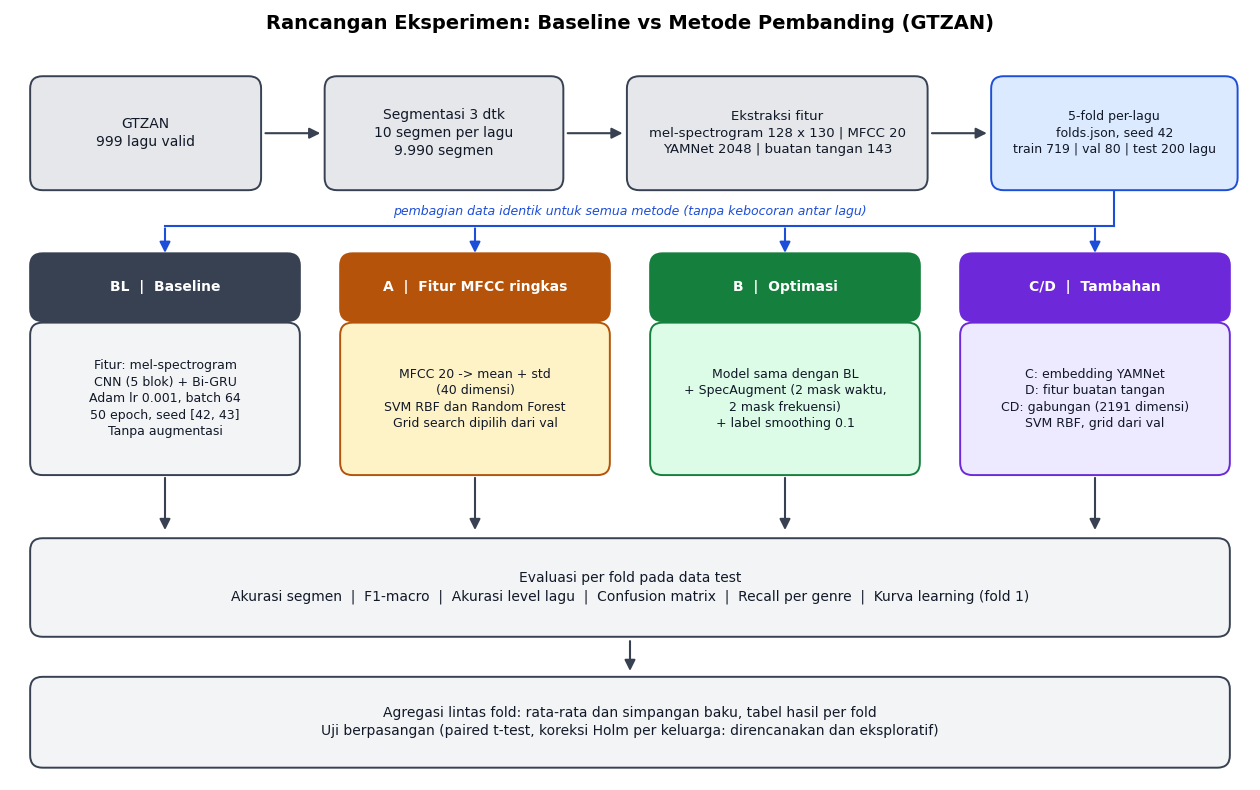

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def titik(n): return f"{n:,}".replace(",", ".")
fi = FOLD_INFO[1]
fig, ax = plt.subplots(figsize=(16, 10)); ax.set_xlim(0, 160); ax.set_ylim(0, 100); ax.axis("off")
def box(x, y, w, h, text, fc="#f3f4f6", ec="#374151", fs=10, bold=False, tc="#111827"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4,rounding_size=1.6", fc=fc, ec=ec, lw=1.4))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal", color=tc, linespacing=1.35)
def panah(x1, y1, x2, y2, c="#374151"):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=16, lw=1.5, color=c))

ax.text(80, 97.5, "Rancangan Eksperimen: Baseline vs Metode Pembanding (GTZAN)", ha="center", fontsize=14, fontweight="bold")
y1, h1 = 77, 14
box(3, y1, 29, h1, f"GTZAN\n{len(trk)} lagu valid", fc="#e5e7eb")
box(41, y1, 30, h1, f"Segmentasi {SEG_SEC} dtk\n{N_SEG} segmen per lagu\n{titik(len(seg))} segmen", fc="#e5e7eb")
box(80, y1, 38, h1, f"Ekstraksi fitur\n{FITUR_MEL.replace('x', ' x ')} | MFCC {n_mfcc}\nYAMNet {E.shape[1]} | buatan tangan {H.shape[1]}", fc="#e5e7eb", fs=9.5)
box(127, y1, 31, h1, f"{N_FOLD}-fold per-lagu\nfolds.json, seed {SEED}\ntrain {fi['lagu_train']} | val {fi['lagu_val']} | test {fi['lagu_test']} lagu", fc="#dbeafe", ec="#1d4ed8", fs=9)
for xa, xb in [(32.6, 40.4), (71.6, 79.4), (118.6, 126.4)]: panah(xa, y1 + h1/2, xb, y1 + h1/2)

y2, h2 = 40, 27; bw = 34; xs = [3, 43, 83, 123]
kolom = [("BL  |  Baseline", "#f3f4f6", "#374151",
          f"Fitur: mel-spectrogram\nCNN ({HP['conv_blocks']} blok) + Bi-GRU\n{HP['optimizer'].capitalize()} lr {HP['lr']}, batch {HP['batch_size']}\n{HP['epochs']} epoch, seed {SEEDS}\nTanpa augmentasi"),
         ("A  |  Fitur MFCC ringkas", "#fef3c7", "#b45309",
          f"MFCC {n_mfcc} -> mean + std\n({2*n_mfcc} dimensi)\nSVM RBF dan Random Forest\nGrid search dipilih dari val"),
         ("B  |  Optimasi", "#dcfce7", "#15803d",
          f"Model sama dengan BL\n+ SpecAugment ({SPEC['n_time']} mask waktu,\n{SPEC['n_freq']} mask frekuensi)\n+ label smoothing {SMOOTH}"),
         ("C/D  |  Tambahan", "#ede9fe", "#6d28d9",
          f"C: embedding YAMNet\nD: fitur buatan tangan\nCD: gabungan ({FITUR['CD_GAB'].shape[1]} dimensi)\nSVM RBF, grid dari val")]
for (jud, fc, ec, isi), x in zip(kolom, xs):
    box(x, y2 + h2 - 7, bw, 8, jud, fc=ec, ec=ec, fs=10, bold=True, tc="white"); box(x, y2, bw, h2 - 8, isi, fc=fc, ec=ec, fs=9)
ax.plot([142.5, 142.5], [y1 - 0.6, 72], color="#1d4ed8", lw=1.5); ax.plot([xs[0] + bw/2, 142.5], [72, 72], color="#1d4ed8", lw=1.5)
for x in xs: panah(x + bw/2, 72, x + bw/2, y2 + h2 + 1.1, c="#1d4ed8")
ax.text(80, 73.4, "pembagian data identik untuk semua metode (tanpa kebocoran antar lagu)", ha="center", fontsize=9, color="#1d4ed8", style="italic")
box(3, 19, 154, 12, "Evaluasi per fold pada data test\nAkurasi segmen  |  F1-macro  |  Akurasi level lagu  |  Confusion matrix  |  Recall per genre  |  Kurva learning (fold 1)", fc="#f3f4f6", ec="#374151", fs=10)
for x in xs: panah(x + bw/2, y2 - 0.4, x + bw/2, 32.1, c="#374151")
box(3, 2, 154, 11, "Agregasi lintas fold: rata-rata dan simpangan baku, tabel hasil per fold\nUji berpasangan (paired t-test, koreksi Holm per keluarga: direncanakan dan eksploratif)", fc="#f3f4f6", ec="#374151", fs=10)
panah(80, 18.4, 80, 13.8)
plt.savefig(os.path.join(WORK_DIR, "fig_diagram_alur.png"), dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

## 3. Baseline (BL): CNN + Bi-GRU pada mel-spectrogram
Setiap fold langsung ditulis ke `hasil_baseline.csv`, lengkap dengan prediksi dan riwayat training; fold yang sudah selesai dilewati bila sel dijalankan ulang.

In [10]:
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

RNN_CELL = {"lstm": layers.LSTM, "gru": layers.GRU}

def build_model(rnn="gru", bidirectional=True, input_shape=(130, 128, 1), n_classes=10, hp=None):
    hp = hp or HP
    inp = keras.Input(shape=input_shape); x = inp
    for _ in range(hp["conv_blocks"]):
        x = layers.Conv2D(hp["conv_filters"], hp["kernel"], padding="same", activation="relu")(x)
        x = layers.MaxPooling2D((2, 2), padding="same")(x)
        x = layers.Dropout(hp["dropout"])(x)
    t, f, c = x.shape[1], x.shape[2], x.shape[3]
    x = layers.Reshape((t, f * c))(x)
    for u in hp["rnn_units"]:
        cell = RNN_CELL[rnn](u, return_sequences=True)
        x = layers.Bidirectional(cell)(x) if bidirectional else cell(x)
    x = layers.Flatten()(x)
    x = layers.Dense(hp["dense_units"], activation="relu")(x)
    x = layers.Dropout(hp["dropout"])(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(hp["lr"]),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def sudah(path, metode, k, seed=SEED):
    if not os.path.exists(path): return False
    r = pd.read_csv(path)
    return bool(((r.metode == metode) & (r.fold == k) & (r.seed == seed)).any())

def evaluasi_dan_simpan(metode, k, seed, h, prob, yte, res_path, pred_dir):
    """Hitung metrik test, simpan baris hasil, prediksi, dan riwayat training."""
    pred = prob.argmax(1)
    acc = accuracy_score(yte, pred)
    f1 = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)[2]
    df = pd.DataFrame(prob); df["track"] = seg.track_id.values[FOLDS[k]["test"]]; df["y"] = yte
    g = df.groupby("track")
    track_acc = accuracy_score(g.y.first(), g[list(range(prob.shape[1]))].mean().values.argmax(1))
    row = dict(metode=metode, fold=k, seed=seed, test_acc=round(acc, 4), f1_macro=round(f1, 4), track_acc=round(track_acc, 4),
               best_epoch=int(np.argmax(h.history["val_accuracy"])) + 1)
    pd.DataFrame([row]).to_csv(res_path, mode="a", header=not os.path.exists(res_path), index=False)
    np.save(os.path.join(pred_dir, f"{metode}_fold{k}_s{seed}.npy"), np.stack([yte, pred]))
    hist = {key: [float(v) for v in vals] for key, vals in h.history.items()}; hist["test_acc"] = float(acc)
    with open(os.path.join(HIST_DIR, f"{metode}_fold{k}_s{seed}.json"), "w") as fh: json.dump(hist, fh)
    return row

def run_fold(metode, k, F, rnn="gru", bi=True, hp=None, seed=SEED, verbose=0):
    hp = hp or HP
    set_seed(seed); keras.backend.clear_session()
    d = get_fold_data(F, k)
    (Xtr, ytr), (Xva, yva), (Xte, yte) = d["train"], d["val"], d["test"]
    model = build_model(rnn, bi, input_shape=Xtr.shape[1:], hp=hp)
    best = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=hp["epochs"],
                                         restore_best_weights=True, mode="max")
    t0 = time.time()
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=hp["epochs"],
                  batch_size=hp["batch_size"], callbacks=[best], verbose=verbose)
    menit = (time.time() - t0) / 60
    row = evaluasi_dan_simpan(metode, k, seed, h, model.predict(Xte, batch_size=256, verbose=0), yte, RES_PATH, PRED_DIR)
    row["train_min"] = round(menit, 1)
    return row

In [11]:
for seed in SEEDS:
    for k in range(1, N_FOLD + 1):
        if sudah(RES_PATH, "BL", k, seed):
            print(f"BL fold {k} seed {seed}: sudah ada, dilewati"); continue
        r = run_fold("BL", k, F, seed=seed)
        print(f"[BL fold {k}/{N_FOLD} seed {seed}] best_ep {r['best_epoch']:2d} | test_acc {r['test_acc']:.4f} | "
              f"f1 {r['f1_macro']:.4f} | track_acc {r['track_acc']:.4f} | {r['train_min']:.1f} mnt")

R = pd.read_csv(RES_PATH)
print("\nRingkasan baseline:")
print(R[["test_acc", "f1_macro", "track_acc"]].agg(["mean", "std"]).round(4))

E0000 00:00:1794254806.745571      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[BL fold 1/5 seed 42] best_ep 34 | test_acc 0.8420 | f1 0.8413 | track_acc 0.8800 | 17.2 mnt


E0000 00:00:1794255844.386030      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[BL fold 2/5 seed 42] best_ep 14 | test_acc 0.8120 | f1 0.8131 | track_acc 0.8750 | 17.1 mnt


E0000 00:00:1794256875.871998      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[BL fold 3/5 seed 42] best_ep 18 | test_acc 0.7920 | f1 0.7916 | track_acc 0.8400 | 17.2 mnt


... (10 outputs left out)

E0000 00:00:1794263073.266762      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[BL fold 4/5 seed 43] best_ep 35 | test_acc 0.8135 | f1 0.8128 | track_acc 0.8900 | 17.1 mnt


E0000 00:00:1794264102.726580      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[BL fold 5/5 seed 43] best_ep 43 | test_acc 0.7925 | f1 0.7930 | track_acc 0.8291 | 17.0 mnt

Ringkasan baseline:
      test_acc  f1_macro  track_acc
mean    0.8134    0.8129     0.8634
std     0.0158    0.0156     0.0205


## 4. Pendekatan A: MFCC (mean + std) + SVM / Random Forest
Model klasik dilatih **hanya pada data train** dan hiperparameternya dipilih dari **data val**, sama seperti baseline yang memakai val untuk memilih epoch, sehingga jumlah data latihnya setara.

In [12]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# ringkas sumbu waktu -> mean dan std tiap koefisien
Z = np.concatenate([M.mean(axis=2), M.std(axis=2)], axis=1).astype(np.float32)
print("Z:", Z.shape, "| NaN:", int(np.isnan(Z).sum()))

def fold_xy(Z, k):
    sp = FOLDS[k]
    sc = StandardScaler().fit(Z[sp["train"]])            # statistik hanya dari train
    return {p: (sc.transform(Z[sp[p]]), y_seg[sp[p]]) for p in ("train", "val", "test")}

Z: (9990, 40) | NaN: 0


In [13]:
def make_model(metode, final=False, **p):
    if metode == "A_SVM":
        return SVC(kernel="rbf", probability=final, random_state=SEED, **p)
    return RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **p)

def run_fold_A(metode, k):
    d = fold_xy(Z, k)
    (Xtr, ytr), (Xva, yva), (Xte, yte) = d["train"], d["val"], d["test"]

    # pilih hiperparameter terbaik berdasarkan akurasi VAL (test tidak disentuh)
    best_acc, best_p = -1, None
    for p in GRID[metode]:
        a = accuracy_score(yva, make_model(metode, **p).fit(Xtr, ytr).predict(Xva))
        if a > best_acc: best_acc, best_p = a, p

    m = make_model(metode, final=True, **best_p).fit(Xtr, ytr)
    pred, prob = m.predict(Xte), m.predict_proba(Xte)
    acc = accuracy_score(yte, pred)
    f1 = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)[2]
    df = pd.DataFrame(prob); df["track"] = seg.track_id.values[FOLDS[k]["test"]]; df["y"] = yte
    g = df.groupby("track")
    track_acc = accuracy_score(g.y.first(), g[list(range(prob.shape[1]))].mean().values.argmax(1))

    row = dict(metode=metode, fold=k, seed=SEED, test_acc=round(acc, 4), f1_macro=round(f1, 4),
               track_acc=round(track_acc, 4), val_acc=round(best_acc, 4), params=json.dumps(best_p))
    pd.DataFrame([row]).to_csv(RES_A, mode="a", header=not os.path.exists(RES_A), index=False)
    np.save(os.path.join(PRED_A, f"{metode}_fold{k}_s{SEED}.npy"), np.stack([yte, pred]))
    return row

for metode in GRID:
    for k in range(1, N_FOLD + 1):
        if sudah(RES_A, metode, k):
            print(f"{metode} fold {k}: sudah ada, dilewati"); continue
        t0 = time.time(); r = run_fold_A(metode, k)
        print(f"[{metode} fold {k}/{N_FOLD}] val {r['val_acc']:.4f} | test {r['test_acc']:.4f} | "
              f"f1 {r['f1_macro']:.4f} | track {r['track_acc']:.4f} | {r['params']} | {time.time()-t0:.0f} dtk")

RA = pd.read_csv(RES_A)
print("\nRingkasan pendekatan A:")
print(RA.groupby("metode")[["test_acc", "f1_macro", "track_acc"]].agg(["mean", "std"]).round(4))

[A_SVM fold 1/5] val 0.6462 | test 0.6600 | f1 0.6572 | track 0.7800 | {"C": 100, "gamma": 0.005} | 62 dtk
[A_SVM fold 2/5] val 0.6575 | test 0.6475 | f1 0.6435 | track 0.7400 | {"C": 1, "gamma": 0.025} | 63 dtk
[A_SVM fold 3/5] val 0.6613 | test 0.6800 | f1 0.6757 | track 0.7700 | {"C": 100, "gamma": 0.005} | 61 dtk
[A_SVM fold 4/5] val 0.6388 | test 0.7145 | f1 0.7136 | track 0.8150 | {"C": 100, "gamma": 0.005} | 63 dtk
[A_SVM fold 5/5] val 0.7063 | test 0.6518 | f1 0.6469 | track 0.7286 | {"C": 10, "gamma": 0.005} | 61 dtk
[A_RF fold 1/5] val 0.6062 | test 0.6450 | f1 0.6369 | track 0.7250 | {"max_depth": null, "min_samples_leaf": 1} | 31 dtk
[A_RF fold 2/5] val 0.6012 | test 0.6185 | f1 0.6099 | track 0.6800 | {"max_depth": null, "min_samples_leaf": 3} | 31 dtk
[A_RF fold 3/5] val 0.6400 | test 0.6645 | f1 0.6538 | track 0.7150 | {"max_depth": 20, "min_samples_leaf": 1} | 31 dtk
[A_RF fold 4/5] val 0.5950 | test 0.6910 | f1 0.6845 | track 0.7600 | {"max_depth": null, "min_samples_l

## 5. Pendekatan B: baseline + SpecAugment + label smoothing
Hanya dua hal yang berbeda dari BL: (i) *time/frequency masking* acak pada input (aktif hanya saat training; parameter di `SPEC`) dan (ii) label smoothing (`SMOOTH`) pada loss. Arsitektur, hiperparameter, jumlah epoch, seed, dan fold sama dengan BL.

In [14]:
from tensorflow.keras.utils import to_categorical

class SpecAugment(layers.Layer):
    """Time & frequency masking. Hanya aktif saat training."""
    def __init__(self, n_time=2, max_time=10, n_freq=2, max_freq=12, **kw):
        super().__init__(**kw)
        self.n_time, self.max_time = n_time, max_time
        self.n_freq, self.max_freq = n_freq, max_freq

    def call(self, x, training=None):
        if not training:
            return x
        B = tf.shape(x)[0]
        T, Fq = x.shape[1], x.shape[2]
        mask = tf.ones_like(x)
        for _ in range(self.n_time):
            w = tf.cast(tf.random.uniform([B, 1, 1, 1]) * (self.max_time + 1), tf.int32)
            s = tf.cast(tf.random.uniform([B, 1, 1, 1]) * tf.cast(T - w + 1, tf.float32), tf.int32)
            t = tf.reshape(tf.range(T), [1, T, 1, 1])
            mask *= tf.cast(tf.logical_or(t < s, t >= s + w), x.dtype)
        for _ in range(self.n_freq):
            w = tf.cast(tf.random.uniform([B, 1, 1, 1]) * (self.max_freq + 1), tf.int32)
            s = tf.cast(tf.random.uniform([B, 1, 1, 1]) * tf.cast(Fq - w + 1, tf.float32), tf.int32)
            f = tf.reshape(tf.range(Fq), [1, 1, Fq, 1])
            mask *= tf.cast(tf.logical_or(f < s, f >= s + w), x.dtype)
        return x * mask          # area yang di-mask bernilai 0 = rata-rata setelah z-score

def build_model_B(rnn="gru", bidirectional=True, input_shape=(130, 128, 1), n_classes=10, hp=None, smoothing=SMOOTH):
    hp = hp or HP
    inp = keras.Input(shape=input_shape)
    x = SpecAugment(**SPEC, name="specaug")(inp)
    for _ in range(hp["conv_blocks"]):
        x = layers.Conv2D(hp["conv_filters"], hp["kernel"], padding="same", activation="relu")(x)
        x = layers.MaxPooling2D((2, 2), padding="same")(x)
        x = layers.Dropout(hp["dropout"])(x)
    t, f, c = x.shape[1], x.shape[2], x.shape[3]
    x = layers.Reshape((t, f * c))(x)
    for u in hp["rnn_units"]:
        cell = RNN_CELL[rnn](u, return_sequences=True)
        x = layers.Bidirectional(cell)(x) if bidirectional else cell(x)
    x = layers.Flatten()(x)
    x = layers.Dense(hp["dense_units"], activation="relu")(x)
    x = layers.Dropout(hp["dropout"])(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(hp["lr"]),
                  loss=keras.losses.CategoricalCrossentropy(label_smoothing=smoothing),
                  metrics=["accuracy"])
    return model

def run_fold_B(metode, k, F, hp=None, seed=SEED, verbose=0):
    hp = hp or HP
    set_seed(seed); keras.backend.clear_session()
    d = get_fold_data(F, k)
    (Xtr, ytr), (Xva, yva), (Xte, yte) = d["train"], d["val"], d["test"]
    model = build_model_B(input_shape=Xtr.shape[1:], hp=hp)
    best = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=hp["epochs"],
                                         restore_best_weights=True, mode="max")
    t0 = time.time()
    h = model.fit(Xtr, to_categorical(ytr, 10), validation_data=(Xva, to_categorical(yva, 10)),
                  epochs=hp["epochs"], batch_size=hp["batch_size"], callbacks=[best], verbose=verbose)
    menit = (time.time() - t0) / 60
    row = evaluasi_dan_simpan(metode, k, seed, h, model.predict(Xte, batch_size=256, verbose=0), yte, RES_B, PRED_B)
    row["train_min"] = round(menit, 1)
    return row

In [15]:
for seed in SEEDS:
    for k in range(1, N_FOLD + 1):
        if sudah(RES_B, "B", k, seed):
            print(f"B fold {k} seed {seed}: sudah ada, dilewati"); continue
        r = run_fold_B("B", k, F, seed=seed)
        print(f"[B fold {k}/{N_FOLD} seed {seed}] best_ep {r['best_epoch']:2d} | test_acc {r['test_acc']:.4f} | "
              f"f1 {r['f1_macro']:.4f} | track_acc {r['track_acc']:.4f} | {r['train_min']:.1f} mnt")

R = pd.read_csv(RES_B)
print("\nRingkasan pendekatan B:")
print(R[["test_acc", "f1_macro", "track_acc"]].agg(["mean", "std"]).round(4))

E0000 00:00:1794265595.273206      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[B fold 1/5 seed 42] best_ep 38 | test_acc 0.8385 | f1 0.8371 | track_acc 0.8900 | 17.1 mnt


E0000 00:00:1794266628.777310      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[B fold 2/5 seed 42] best_ep 48 | test_acc 0.8350 | f1 0.8335 | track_acc 0.8800 | 17.2 mnt


E0000 00:00:1794267669.046746      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[B fold 3/5 seed 42] best_ep 28 | test_acc 0.8010 | f1 0.8003 | track_acc 0.8450 | 17.0 mnt


... (10 outputs left out)

E0000 00:00:1794273803.716310      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[B fold 4/5 seed 43] best_ep 27 | test_acc 0.8135 | f1 0.8130 | track_acc 0.8600 | 17.0 mnt


E0000 00:00:1794274826.547810      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


[B fold 5/5 seed 43] best_ep 30 | test_acc 0.8136 | f1 0.8125 | track_acc 0.8593 | 17.1 mnt

Ringkasan pendekatan B:
      test_acc  f1_macro  track_acc
mean    0.8210    0.8203     0.8654
std     0.0168    0.0168     0.0222


## 6. Metode tambahan (eksploratif): C_YAM, D_HAND, CD_GAB
Tiga metode ini membentuk **ablasi**: embedding YAMNet saja, fitur buatan tangan saja, dan gabungan, sehingga terlihat sumber peningkatan (jika ada). Standardisasi dari data train, hiperparameter SVM dari data val, test tidak disentuh sampai evaluasi akhir. Metode ini memakai **data eksternal** (YAMNet dilatih pada AudioSet) dan CPU untuk klasifikasi.

In [16]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def skor_val(C, g, Xtr, ytr, Xva, yva):
    return accuracy_score(yva, SVC(kernel="rbf", C=C, gamma=g).fit(Xtr, ytr).predict(Xva))

def run_fold_C(metode, k):
    X = FITUR[metode]; sp = FOLDS[k]
    sc = StandardScaler().fit(X[sp["train"]])
    Xtr, Xva, Xte = (sc.transform(X[sp[p]]) for p in ("train", "val", "test"))
    ytr, yva, yte = (y_seg[sp[p]] for p in ("train", "val", "test"))
    komb = list(product(GRID_C, [g / X.shape[1] for g in GRID_G]))
    akur = Parallel(n_jobs=-1)(delayed(skor_val)(C, g, Xtr, ytr, Xva, yva) for C, g in komb)
    ib = int(np.argmax(akur)); C_b, g_b = komb[ib]
    m = SVC(kernel="rbf", C=C_b, gamma=g_b, probability=True, random_state=SEED).fit(Xtr, ytr)
    pred, prob = m.predict(Xte), m.predict_proba(Xte)
    acc = accuracy_score(yte, pred)
    f1 = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)[2]
    df = pd.DataFrame(prob, columns=m.classes_); df["track"] = seg.track_id.values[sp["test"]]; df["y"] = yte
    g_ = df.groupby("track")
    track_acc = accuracy_score(g_.y.first(), m.classes_[g_[list(m.classes_)].mean().values.argmax(1)])
    row = dict(metode=metode, fold=k, seed=SEED, test_acc=round(acc, 4), f1_macro=round(f1, 4), track_acc=round(track_acc, 4),
               val_acc=round(akur[ib], 4), params=json.dumps(dict(C=C_b, g=round(g_b * X.shape[1], 3))))
    pd.DataFrame([row]).to_csv(RES_C, mode="a", header=not os.path.exists(RES_C), index=False)
    np.save(os.path.join(PRED_C, f"{metode}_fold{k}_s{SEED}.npy"), np.stack([yte, pred]))
    return row

for metode in BARU:
    for k in range(1, N_FOLD + 1):
        if sudah(RES_C, metode, k):
            print(f"{metode} fold {k}: sudah ada, dilewati"); continue
        t0 = time.time(); r = run_fold_C(metode, k)
        print(f"[{metode} fold {k}/{N_FOLD}] val {r['val_acc']:.4f} | test {r['test_acc']:.4f} | f1 {r['f1_macro']:.4f} | "
              f"track {r['track_acc']:.4f} | {r['params']} | {time.time() - t0:.0f} dtk")

RC = pd.read_csv(RES_C)
print("\nRingkasan metode tambahan:")
print(RC.groupby("metode")[["test_acc", "f1_macro", "track_acc"]].agg(["mean", "std"]).round(4))

[C_YAM fold 1/5] val 0.7863 | test 0.7825 | f1 0.7826 | track 0.8650 | {"C": 1, "g": 0.5} | 268 dtk
[C_YAM fold 2/5] val 0.7950 | test 0.7865 | f1 0.7847 | track 0.8450 | {"C": 1, "g": 1.0} | 261 dtk
[C_YAM fold 3/5] val 0.8013 | test 0.7550 | f1 0.7530 | track 0.8250 | {"C": 1, "g": 0.5} | 256 dtk
[C_YAM fold 4/5] val 0.7788 | test 0.8310 | f1 0.8283 | track 0.9050 | {"C": 1, "g": 1.0} | 282 dtk
[C_YAM fold 5/5] val 0.8050 | test 0.7925 | f1 0.7900 | track 0.8693 | {"C": 100, "g": 1.0} | 266 dtk
[D_HAND fold 1/5] val 0.6837 | test 0.7570 | f1 0.7553 | track 0.8250 | {"C": 10, "g": 1.0} | 46 dtk
[D_HAND fold 2/5] val 0.7588 | test 0.7405 | f1 0.7354 | track 0.8100 | {"C": 1, "g": 1.0} | 46 dtk
[D_HAND fold 3/5] val 0.7762 | test 0.7440 | f1 0.7419 | track 0.8300 | {"C": 10, "g": 1.0} | 46 dtk
[D_HAND fold 4/5] val 0.7188 | test 0.7600 | f1 0.7593 | track 0.8650 | {"C": 10, "g": 0.5} | 40 dtk
[D_HAND fold 5/5] val 0.8087 | test 0.7327 | f1 0.7299 | track 0.8090 | {"C": 1, "g": 1.0} | 47

## 7. Evaluasi
### 7.1 Tabel hasil lintas metode dan lintas fold
Jika memakai lebih dari satu seed, skor tiap fold adalah rata-rata antar seed.

In [17]:
semua_raw = pd.concat([pd.read_csv(p) for p in (RES_PATH, RES_A, RES_B, RES_C)])
semua_raw = semua_raw[semua_raw.metode.isin(METODE)]
print("Seed per metode:", semua_raw.groupby("metode").seed.nunique().to_dict())
semua = semua_raw.groupby(["metode", "fold"], as_index=False)[["test_acc", "f1_macro", "track_acc"]].mean()
for m in METODE: assert sorted(semua[semua.metode == m].fold.tolist()) == list(range(1, N_FOLD + 1)), f"{m}: fold tidak lengkap"
print("Jumlah fold per metode:", semua.groupby("metode").fold.nunique().to_dict())

METRIK = {"test_acc": "Akurasi segmen", "f1_macro": "F1-macro", "track_acc": "Akurasi lagu"}
TABEL = {}
for col, nama in METRIK.items():
    pv = semua.pivot(index="metode", columns="fold", values=col).loc[METODE] * 100
    pv.columns = [f"Fold {c}" for c in pv.columns]
    pv["Rata-rata"] = pv.iloc[:, :N_FOLD].mean(axis=1)
    pv["SD"]        = pv.iloc[:, :N_FOLD].std(axis=1, ddof=1)
    TABEL[nama] = pv.round(2)
    print(f"\n{nama} (%)"); display(TABEL[nama])
    TABEL[nama].to_csv(os.path.join(WORK_DIR, f"tabel_m2_{col}.csv"))

RINGKAS = pd.DataFrame({nama: [f"{TABEL[nama].loc[m, 'Rata-rata']:.2f} ± {TABEL[nama].loc[m, 'SD']:.2f}" for m in METODE]
                        for nama in METRIK.values()}, index=[NAMA[m] for m in METODE])
print(f"\nRingkasan {N_FOLD} fold (rata-rata ± SD, %)"); display(RINGKAS)
RINGKAS.to_csv(os.path.join(WORK_DIR, "tabel_m2_ringkasan.csv"))

Seed per metode: {'A_RF': 1, 'A_SVM': 1, 'B': 2, 'BL': 2, 'CD_GAB': 1, 'C_YAM': 1, 'D_HAND': 1}
Jumlah fold per metode: {'A_RF': 5, 'A_SVM': 5, 'B': 5, 'BL': 5, 'CD_GAB': 5, 'C_YAM': 5, 'D_HAND': 5}

Akurasi segmen (%)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Rata-rata,SD
metode,,,,,,,
BL,82.38,81.45,80.05,82.38,80.46,81.34,1.07
B,82.88,84.15,80.32,82.38,80.76,82.10,1.57
A_SVM,66.00,64.75,68.00,71.45,65.18,67.08,2.75
A_RF,64.50,61.85,66.45,69.10,62.21,64.82,3.03
C_YAM,78.25,78.65,75.50,83.10,79.25,78.95,2.73
D_HAND,75.70,74.05,74.40,76.00,73.27,74.68,1.15
CD_GAB,82.25,82.55,80.80,87.05,83.32,83.19,2.34



F1-macro (%)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Rata-rata,SD
metode,,,,,,,
BL,82.30,81.38,79.97,82.30,80.46,81.29,1.06
B,82.78,84.09,80.24,82.34,80.72,82.03,1.57
A_SVM,65.72,64.35,67.57,71.36,64.69,66.74,2.87
A_RF,63.69,60.99,65.38,68.45,61.13,63.93,3.13
C_YAM,78.26,78.47,75.30,82.83,79.00,78.77,2.69
D_HAND,75.53,73.54,74.19,75.93,72.99,74.44,1.26
CD_GAB,82.27,82.33,80.49,86.95,83.13,83.03,2.39



Akurasi lagu (%)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Rata-rata,SD
metode,,,,,,,
BL,87.00,86.25,84.50,88.75,85.18,86.34,1.66
B,88.25,88.75,83.75,87.00,84.92,86.54,2.15
A_SVM,78.00,74.00,77.00,81.50,72.86,76.67,3.42
A_RF,72.50,68.00,71.50,76.00,69.35,71.47,3.09
C_YAM,86.50,84.50,82.50,90.50,86.93,86.19,2.99
D_HAND,82.50,81.00,83.00,86.50,80.90,82.78,2.27
CD_GAB,90.50,89.50,87.50,93.00,90.95,90.29,2.01



Ringkasan 5 fold (rata-rata ± SD, %)


,Akurasi segmen,F1-macro,Akurasi lagu
BL (CNN+Bi-GRU),81.34 ± 1.07,81.29 ± 1.06,86.34 ± 1.66
B (BL+SpecAug+LS),82.10 ± 1.57,82.03 ± 1.57,86.54 ± 2.15
A_SVM (MFCC+SVM),67.08 ± 2.75,66.74 ± 2.87,76.67 ± 3.42
A_RF (MFCC+RF),64.82 ± 3.03,63.93 ± 3.13,71.47 ± 3.09
C_YAM (YAMNet+SVM),78.95 ± 2.73,78.77 ± 2.69,86.19 ± 2.99
D_HAND (buatan tangan+SVM),74.68 ± 1.15,74.44 ± 1.26,82.78 ± 2.27
CD_GAB (gabungan+SVM),83.19 ± 2.34,83.03 ± 2.39,90.29 ± 2.01


### 7.2 Uji berpasangan antar fold
Unit uji adalah fold; skor kedua metode dipasangkan per fold (pembagian identik). Paired t-test dua sisi, CI 95% selisih rata-rata, effect size *d_z*, dan koreksi Holm **terpisah dalam tiap keluarga** perbandingan dan tiap metrik.

In [18]:
from scipy import stats

PLAN  = [("B", "BL"), ("BL", "A_SVM"), ("BL", "A_RF"), ("B", "A_SVM"), ("B", "A_RF"), ("A_SVM", "A_RF")]
EKSPL = [("CD_GAB", "BL"), ("C_YAM", "BL"), ("D_HAND", "BL"), ("CD_GAB", "B"), ("C_YAM", "B"),
         ("CD_GAB", "C_YAM"), ("CD_GAB", "D_HAND"), ("C_YAM", "D_HAND"), ("D_HAND", "A_SVM")]
def skor(m, col): return semua[semua.metode == m].sort_values("fold")[col].values * 100

def uji(a, b, col, kel):
    x, y = skor(a, col), skor(b, col); d, n = x - y, len(x); sd = d.std(ddof=1)
    if sd == 0:      # selisih identik di semua fold: uji t tidak terdefinisi
        t_stat, p, h, dz = (0.0, 1.0, 0.0, np.nan) if d.mean() == 0 else (np.inf * np.sign(d.mean()), 0.0, 0.0, np.nan)
    else:
        t = stats.ttest_rel(x, y); t_stat, p = t.statistic, t.pvalue
        h, dz = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n), d.mean() / sd
    return dict(keluarga=kel, perbandingan=f"{a} vs {b}", metrik=METRIK[col], selisih=d.mean(), ci95_bawah=d.mean() - h, ci95_atas=d.mean() + h,
                t=t_stat, df=n - 1, p=p, cohen_dz=dz, fold_a_unggul=int((d > 0).sum()), n_fold=n)

def holm(p):
    p = np.asarray(p); adj, run = np.empty(len(p)), 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - r) * p[i]); adj[i] = min(run, 1.0)
    return adj

UJI = pd.DataFrame([uji(a, b, c, kel) for c in METRIK for kel, ps in (("direncanakan", PLAN), ("eksploratif", EKSPL)) for a, b in ps])
UJI["p_holm"] = UJI.groupby(["keluarga", "metrik"]).p.transform(lambda s: holm(s.values))
UJI["signifikan"] = np.where(UJI.p_holm < ALPHA, "ya", "tidak")
UJI.to_csv(os.path.join(WORK_DIR, "uji_berpasangan_m2.csv"), index=False)
for kel in ("direncanakan", "eksploratif"):
    print(f"\nKeluarga {kel} (akurasi segmen):")
    display(UJI[(UJI.keluarga == kel) & (UJI.metrik == "Akurasi segmen")].drop(columns=["keluarga", "metrik"]).round(4).set_index("perbandingan"))
print("\nB vs BL pada semua metrik:")
display(UJI[UJI.perbandingan == "B vs BL"].drop(columns=["keluarga", "perbandingan"]).round(4).set_index("metrik"))
print("Perbandingan eksploratif pada akurasi lagu:")
display(UJI[(UJI.keluarga == "eksploratif") & (UJI.metrik == "Akurasi lagu")].drop(columns=["keluarga", "metrik"]).round(4).set_index("perbandingan"))


Keluarga direncanakan (akurasi segmen):


,selisih,ci95_bawah,ci95_atas,t,df,p,cohen_dz,fold_a_unggul,n_fold,p_holm,signifikan
perbandingan,,,,,,,,,,,
B vs BL,0.755,-0.6130,2.1230,1.5323,4,0.2002,0.6853,4,5,0.2002,tidak
BL vs A_SVM,14.265,11.0115,17.5185,12.1734,4,0.0003,5.4441,5,5,0.0013,ya
BL vs A_RF,16.519,12.9335,20.1045,12.7915,4,0.0002,5.7205,5,5,0.0013,ya
B vs A_SVM,15.020,10.7654,19.2746,9.8016,4,0.0006,4.3834,5,5,0.0020,ya
B vs A_RF,17.274,12.6433,21.9047,10.3571,4,0.0005,4.6319,5,5,0.0020,ya
A_SVM vs A_RF,2.254,1.3753,3.1327,7.1219,4,0.0021,3.1850,5,5,0.0041,ya



Keluarga eksploratif (akurasi segmen):


,selisih,ci95_bawah,ci95_atas,t,df,p,cohen_dz,fold_a_unggul,n_fold,p_holm,signifikan
perbandingan,,,,,,,,,,,
CD_GAB vs BL,1.853,-0.5260,4.2320,2.1626,4,0.0966,0.9671,4,5,0.2284,tidak
C_YAM vs BL,-2.391,-5.0937,0.3117,-2.4563,4,0.0700,-1.0985,1,5,0.2284,tidak
D_HAND vs BL,-6.657,-7.5183,-5.7957,-21.4590,4,0.0000,-9.5967,0,5,0.0003,ya
CD_GAB vs B,1.098,-2.0422,4.2382,0.9708,4,0.3866,0.4342,3,5,0.3866,tidak
C_YAM vs B,-3.146,-6.4443,0.1523,-2.6482,4,0.0571,-1.1843,1,5,0.2284,tidak
CD_GAB vs C_YAM,4.244,3.5069,4.9811,15.9854,4,0.0001,7.1489,5,5,0.0007,ya
CD_GAB vs D_HAND,8.510,5.9415,11.0785,9.1988,4,0.0008,4.1138,5,5,0.0054,ya
C_YAM vs D_HAND,4.266,1.2214,7.3106,3.8903,4,0.0177,1.7398,5,5,0.0884,tidak
D_HAND vs A_SVM,7.608,4.9535,10.2625,7.9574,4,0.0014,3.5587,5,5,0.0081,ya



B vs BL pada semua metrik:


,selisih,ci95_bawah,ci95_atas,t,df,p,cohen_dz,fold_a_unggul,n_fold,p_holm,signifikan
metrik,,,,,,,,,,,
Akurasi segmen,0.755,-0.6130,2.1230,1.5323,4,0.2002,0.6853,4,5,0.2002,tidak
F1-macro,0.748,-0.6238,2.1198,1.5140,4,0.2046,0.6771,5,5,0.2046,tidak
Akurasi lagu,0.200,-1.8870,2.2870,0.2661,4,0.8033,0.1190,2,5,0.8033,tidak


Perbandingan eksploratif pada akurasi lagu:


,selisih,ci95_bawah,ci95_atas,t,df,p,cohen_dz,fold_a_unggul,n_fold,p_holm,signifikan
perbandingan,,,,,,,,,,,
CD_GAB vs BL,3.955,2.5646,5.3454,7.8978,4,0.0014,3.5320,5,5,0.0094,ya
C_YAM vs BL,-0.149,-2.4169,2.1189,-0.1824,4,0.8641,-0.0816,2,5,1.0000,tidak
D_HAND vs BL,-3.555,-5.5388,-1.5712,-4.9754,4,0.0076,-2.2251,0,5,0.0381,ya
CD_GAB vs B,3.755,0.8771,6.6329,3.6227,4,0.0223,1.6201,5,5,0.0892,tidak
C_YAM vs B,-0.349,-4.1936,3.4956,-0.2520,4,0.8134,-0.1127,2,5,1.0000,tidak
CD_GAB vs C_YAM,4.104,2.8322,5.3758,8.9596,4,0.0009,4.0068,5,5,0.0069,ya
CD_GAB vs D_HAND,7.510,4.8942,10.1258,7.9713,4,0.0013,3.5649,5,5,0.0094,ya
C_YAM vs D_HAND,3.406,0.4379,6.3741,3.1861,4,0.0333,1.4248,4,5,0.1000,tidak
D_HAND vs A_SVM,6.108,4.3137,7.9023,9.4512,4,0.0007,4.2267,5,5,0.0063,ya


### 7.3 Confusion matrix gabungan dan recall per genre

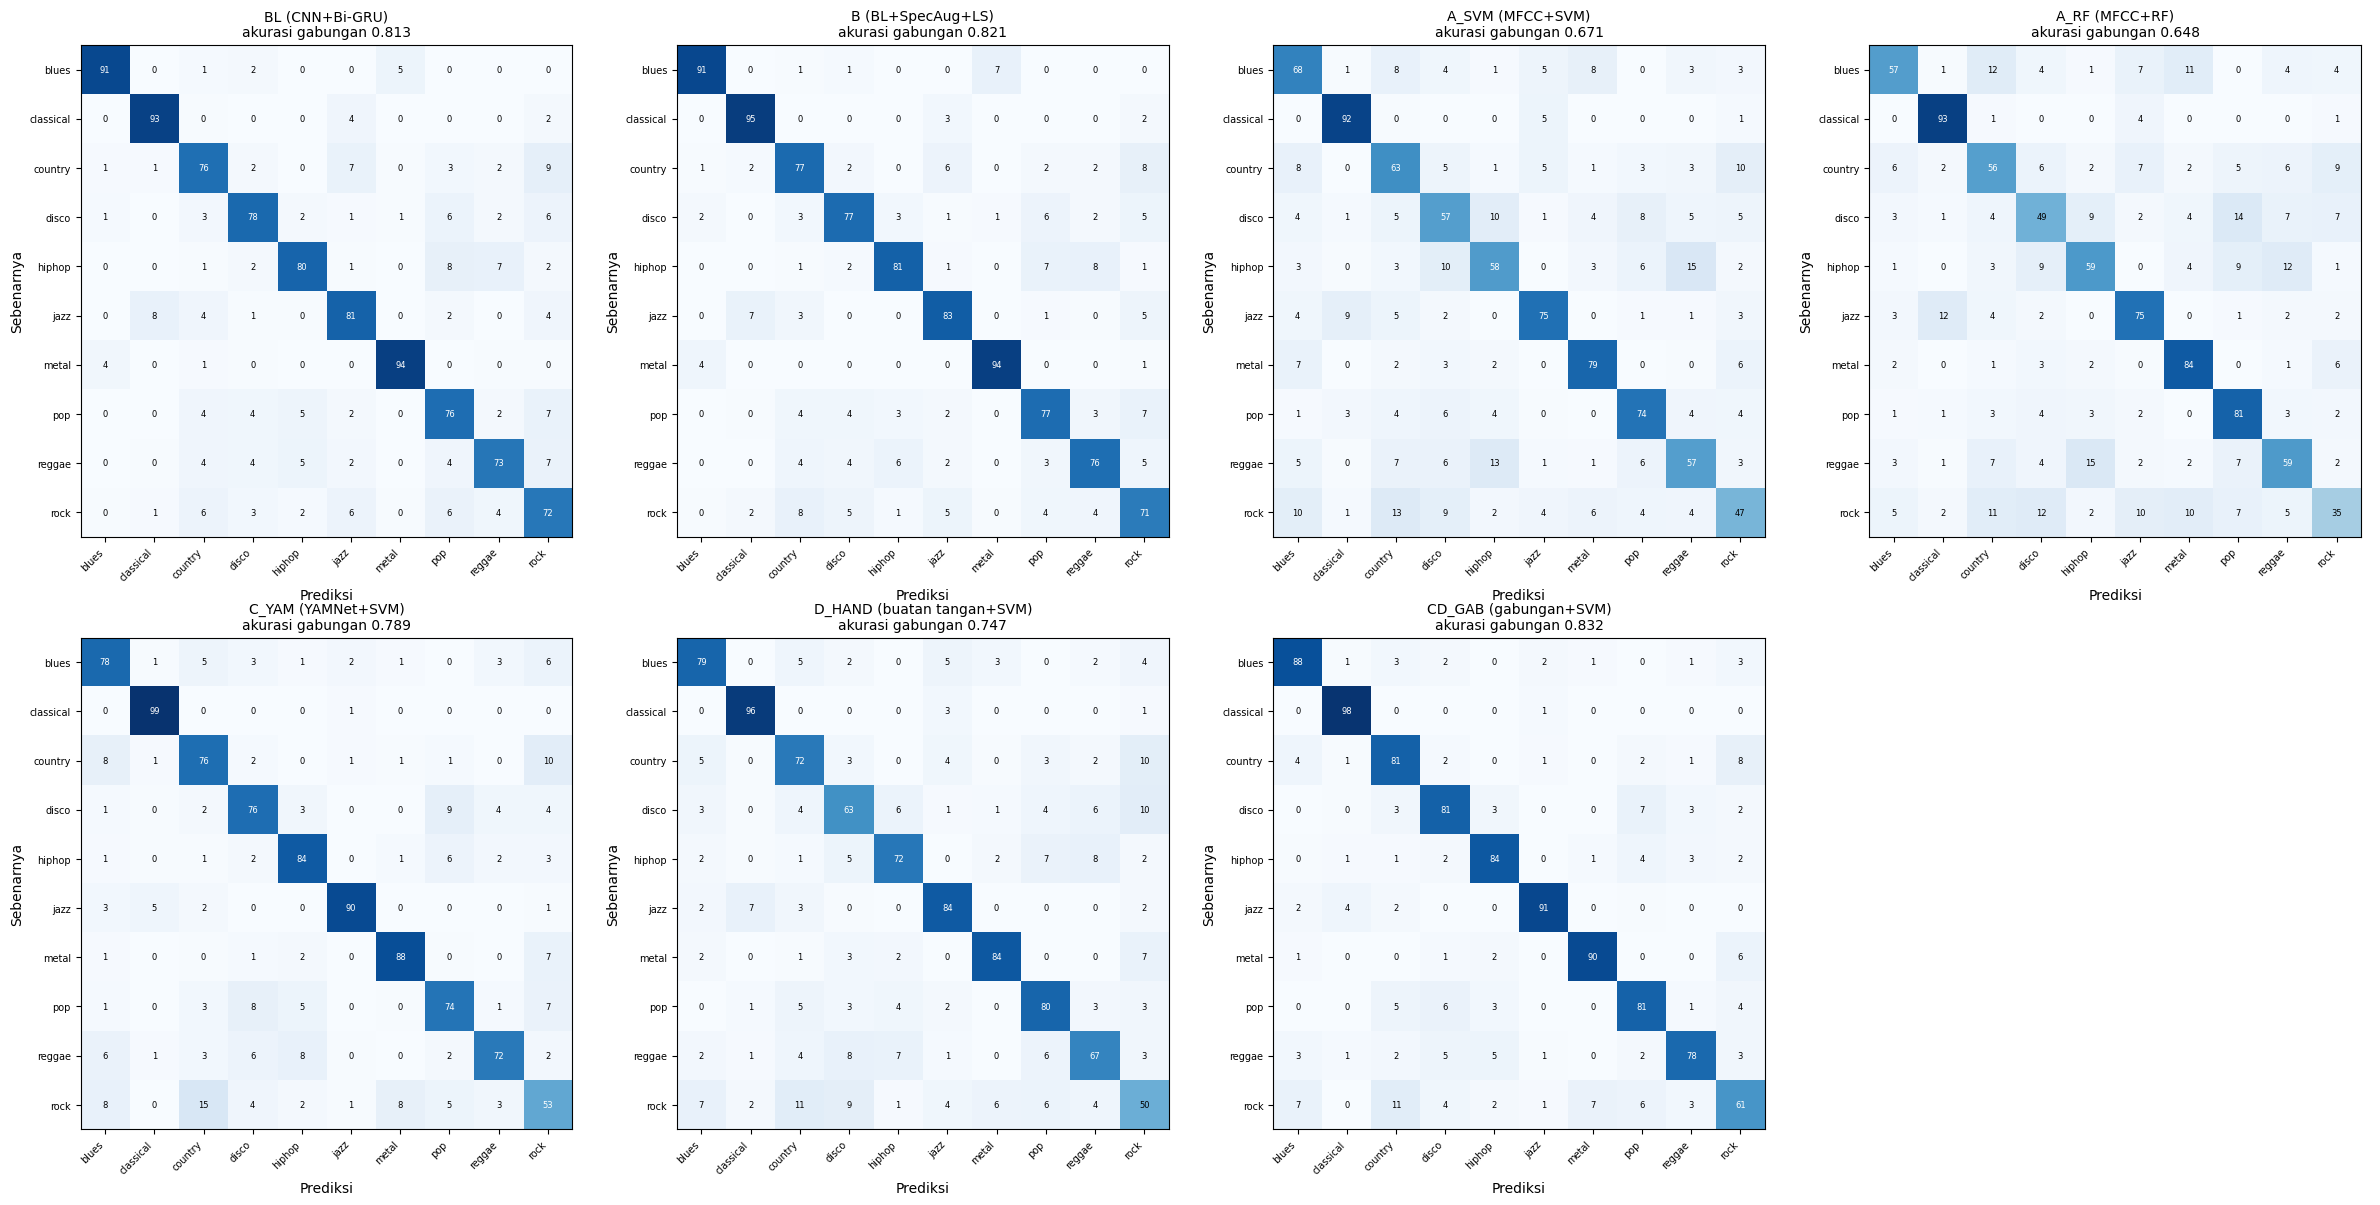

Recall per genre (%), gabungan seluruh fold:


,BL,B,A_SVM,A_RF,C_YAM,D_HAND,CD_GAB,B - BL,CD_GAB - BL
blues,90.6,90.6,68.0,57.2,77.9,79.4,87.5,0.0,-3.1
classical,93.2,94.7,92.5,93.4,98.7,95.7,98.3,1.5,5.1
country,75.5,77.4,63.4,56.3,76.1,71.5,81.1,1.9,5.6
disco,78.0,77.0,56.7,48.8,76.5,62.8,80.9,-1.0,2.9
hiphop,79.8,81.2,58.2,59.2,83.9,72.3,84.4,1.4,4.6
jazz,80.8,82.6,75.4,74.9,89.7,83.9,91.0,1.8,10.2
metal,94.1,94.0,79.1,83.7,88.4,84.4,89.7,-0.1,-4.4
pop,76.2,76.8,74.1,80.8,73.6,79.6,80.6,0.6,4.4
reggae,72.9,75.9,56.9,58.9,71.7,67.4,77.9,3.0,5.0
rock,72.3,70.8,46.6,35.1,53.1,49.9,60.6,-1.5,-11.7


In [19]:
from sklearn.metrics import confusion_matrix

SUMBER = {"BL": (PRED_DIR, "BL"), "A_SVM": (PRED_A, "A_SVM"), "A_RF": (PRED_A, "A_RF"), "B": (PRED_B, "B"),
          "C_YAM": (PRED_C, "C_YAM"), "D_HAND": (PRED_C, "D_HAND"), "CD_GAB": (PRED_C, "CD_GAB")}
def muat_pred(m):
    folder, prefix = SUMBER[m]; ys, ps = [], []
    for k in range(1, N_FOLD + 1):
        for pth in sorted(glob.glob(os.path.join(folder, f"{prefix}_fold{k}_s*.npy"))):
            a = np.load(pth); ys.append(a[0]); ps.append(a[1])
    return np.concatenate(ys).astype(int), np.concatenate(ps).astype(int)

RECALL = {}
fig, axes = plt.subplots(2, 4, figsize=(24, 12)); axes = axes.ravel()
for ax_, m in zip(axes, METODE):
    y, p = muat_pred(m)
    cm = confusion_matrix(y, p, labels=range(len(GENRES))); cmn = cm / cm.sum(axis=1, keepdims=True)
    RECALL[m] = np.diag(cmn)
    im = ax_.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    ax_.set_title(f"{NAMA[m]}\nakurasi gabungan {np.trace(cm)/cm.sum():.3f}", fontsize=10)
    ax_.set_xticks(range(len(GENRES))); ax_.set_yticks(range(len(GENRES)))
    ax_.set_xticklabels(GENRES, rotation=45, ha="right", fontsize=7); ax_.set_yticklabels(GENRES, fontsize=7)
    ax_.set_xlabel("Prediksi"); ax_.set_ylabel("Sebenarnya")
    for i in range(len(GENRES)):
        for j in range(len(GENRES)):
            ax_.text(j, i, f"{cmn[i, j]*100:.0f}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.5 else "black")
for ax_ in axes[len(METODE):]: ax_.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_confusion_m2.png"), dpi=200, bbox_inches="tight"); plt.show()

REC = pd.DataFrame(RECALL, index=GENRES).mul(100).round(1)[METODE]
REC["B - BL"] = (REC["B"] - REC["BL"]).round(1)
REC["CD_GAB - BL"] = (REC["CD_GAB"] - REC["BL"]).round(1)
print("Recall per genre (%), gabungan seluruh fold:"); display(REC)
REC.to_csv(os.path.join(WORK_DIR, "tabel_m2_recall_per_genre.csv"))

## 8. Kurva learning (fold 1) dan ringkasan hasil
Riwayat training BL dan B pada fold 1 diambil dari run utama (seed pertama di `SEEDS`), sehingga kurva berasal dari model yang sama dengan angka pada tabel.

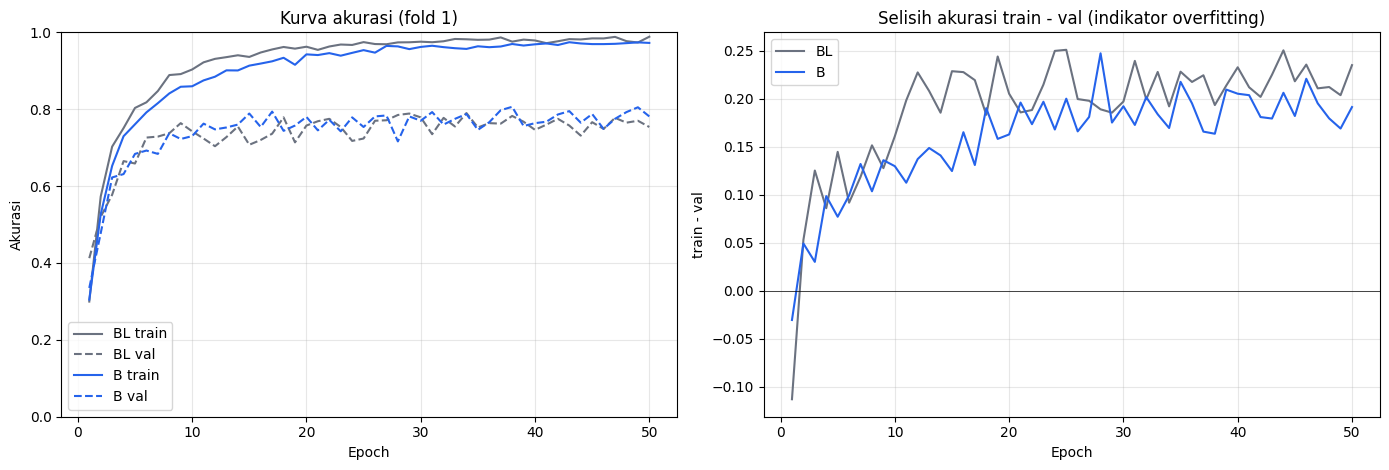

,epoch_terbaik,val_terbaik,train_akhir,gap_akhir,test_acc
BL,34.0,0.7900,0.9886,0.2348,0.8420
B,38.0,0.8062,0.9725,0.1912,0.8385


In [20]:
H = {n: json.load(open(os.path.join(HIST_DIR, f"{n}_fold1_s{SEEDS[0]}.json"))) for n in ["BL", "B"]}
warna = {"BL": "#6b7280", "B": "#2563eb"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for n, h in H.items():
    ep = np.arange(1, len(h["accuracy"]) + 1); tr, va = np.array(h["accuracy"]), np.array(h["val_accuracy"])
    ax[0].plot(ep, tr, color=warna[n], label=f"{n} train"); ax[0].plot(ep, va, color=warna[n], ls="--", label=f"{n} val")
    ax[1].plot(ep, tr - va, color=warna[n], label=n)
ax[0].set_title("Kurva akurasi (fold 1)"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Akurasi"); ax[0].set_ylim(0, 1.0); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].set_title("Selisih akurasi train - val (indikator overfitting)"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("train - val")
ax[1].axhline(0, color="k", lw=0.5); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "fig_kurva_learning_fold1.png"), dpi=200); plt.show()

KURVA = {}
for n, h in H.items():
    va = np.array(h["val_accuracy"]); be = int(va.argmax())
    KURVA[n] = dict(epoch_terbaik=be + 1, val_terbaik=va[be], train_akhir=h["accuracy"][-1],
                    gap_akhir=h["accuracy"][-1] - va[-1], test_acc=h["test_acc"])
display(pd.DataFrame(KURVA).T.round(4))

### Ringkasan hasil (kalimat dibangkitkan dari hasil di atas)
Setiap angka dan label signifikan dihitung oleh kode. Jika hasil berubah, kalimat ikut berubah.

In [21]:
def idn(x, d=2, plus=False): return (f"{x:+.{d}f}" if plus else f"{x:.{d}f}").replace(".", ",")
def sig(p): return "signifikan" if p < ALPHA else "belum signifikan"
def baris(kel, pas, metrik="Akurasi segmen"):
    return UJI[(UJI.keluarga == kel) & (UJI.perbandingan == pas) & (UJI.metrik == metrik)].iloc[0]
S = TABEL["Akurasi segmen"]; STR = TABEL["Akurasi lagu"]

print(f"1. Hasil lintas {N_FOLD} fold (akurasi segmen dan akurasi lagu, rata-rata ± SD):")
for m in S.sort_values("Rata-rata", ascending=False).index:
    print(f"   - {NAMA[m]}: {idn(S.loc[m, 'Rata-rata'])} ± {idn(S.loc[m, 'SD'])} | lagu {idn(STR.loc[m, 'Rata-rata'])} ± {idn(STR.loc[m, 'SD'])}")

r = baris("direncanakan", "B vs BL"); kata = "memuat nol" if r.ci95_bawah <= 0 <= r.ci95_atas else "tidak memuat nol"
print(f"\n2. Keluarga direncanakan. B vs BL: selisih {idn(r.selisih, plus=True)} poin (CI 95% {idn(r.ci95_bawah, plus=True)} sampai {idn(r.ci95_atas, plus=True)}; CI {kata}); "
      f"B lebih baik di {int(r.fold_a_unggul)} dari {int(r.n_fold)} fold; t = {idn(r.t)}, p = {idn(r.p, 3)}, p Holm = {idn(r.p_holm, 3)}, d_z = {idn(r.cohen_dz)} -> {sig(r.p_holm)} pada α = {idn(ALPHA)}.")
for nm in ("F1-macro", "Akurasi lagu"):
    rr = baris("direncanakan", "B vs BL", nm); print(f"   {nm}: selisih {idn(rr.selisih, plus=True)} poin, p = {idn(rr.p, 3)} ({sig(rr.p_holm)}).")
print("   Pendekatan A (fitur MFCC ringkas):")
for pas in ("BL vs A_SVM", "BL vs A_RF", "B vs A_SVM", "B vs A_RF", "A_SVM vs A_RF"):
    rr = baris("direncanakan", pas); print(f"   - {pas}: selisih {idn(rr.selisih, plus=True)} poin, p Holm = {idn(rr.p_holm, 4)} ({sig(rr.p_holm)}), unggul di {int(rr.fold_a_unggul)} dari {int(rr.n_fold)} fold.")

print("\n3. Keluarga eksploratif (metode tambahan), dibanding baseline:")
for m in BARU:
    for nm in ("Akurasi segmen", "Akurasi lagu"):
        rr = baris("eksploratif", f"{m} vs BL", nm); arah = "lebih tinggi" if rr.selisih > 0 else "lebih rendah"
        kk = "memuat nol" if rr.ci95_bawah <= 0 <= rr.ci95_atas else "tidak memuat nol"
        print(f"   - {m} ({nm.lower()}): {arah} {idn(abs(rr.selisih))} poin (CI 95% {idn(rr.ci95_bawah, plus=True)} sampai {idn(rr.ci95_atas, plus=True)}; CI {kk}), "
              f"unggul di {int(rr.fold_a_unggul)} dari {int(rr.n_fold)} fold; p Holm = {idn(rr.p_holm, 4)} -> {sig(rr.p_holm)}.")
lebih = [m for m in BARU if baris("eksploratif", f"{m} vs BL").selisih > 0 and baris("eksploratif", f"{m} vs BL").p_holm < ALPHA]
print("   Kesimpulan: " + (f"metode tambahan yang signifikan lebih baik dari BL (akurasi segmen): {', '.join(lebih)}." if lebih else "tidak ada metode tambahan yang terbukti signifikan lebih baik dari BL pada akurasi segmen."))
print("   Ablasi (akurasi segmen):")
for pas in ("CD_GAB vs C_YAM", "CD_GAB vs D_HAND", "C_YAM vs D_HAND", "D_HAND vs A_SVM"):
    rr = baris("eksploratif", pas); print(f"   - {pas}: selisih {idn(rr.selisih, plus=True)} poin, p Holm = {idn(rr.p_holm, 4)} ({sig(rr.p_holm)}), unggul di {int(rr.fold_a_unggul)} dari {int(rr.n_fold)} fold.")

mudah, sulit = REC["BL"].idxmax(), REC["BL"].idxmin(); sel = REC["B - BL"]; sel2 = REC["CD_GAB - BL"]
print(f"\n4. Per genre: BL paling mudah pada {mudah} ({idn(REC.loc[mudah, 'BL'], 1)}%) dan paling sulit pada {sulit} ({idn(REC.loc[sulit, 'BL'], 1)}%). "
      f"B lebih baik daripada BL di {int((sel > 0).sum())} dari {len(sel)} genre (terbesar {sel.idxmax()} {idn(sel.max(), 1, True)}, terkecil {sel.idxmin()} {idn(sel.min(), 1, True)} poin). "
      f"CD_GAB lebih baik daripada BL di {int((sel2 > 0).sum())} dari {len(sel2)} genre (terbesar {sel2.idxmax()} {idn(sel2.max(), 1, True)}, terkecil {sel2.idxmin()} {idn(sel2.min(), 1, True)} poin).")

kb, kk_ = KURVA["B"], KURVA["BL"]
lebih_k = "lebih kecil" if kb["gap_akhir"] < kk_["gap_akhir"] else "lebih besar atau sama"
print(f"\n5. Kurva learning fold 1: val terbaik BL {idn(kk_['val_terbaik'], 3)} (epoch {kk_['epoch_terbaik']}), B {idn(kb['val_terbaik'], 3)} (epoch {kb['epoch_terbaik']}). "
      f"Selisih train-val pada epoch terakhir: BL {idn(kk_['gap_akhir'], 3)}, B {idn(kb['gap_akhir'], 3)} (B {lebih_k}).")

1. Hasil lintas 5 fold (akurasi segmen dan akurasi lagu, rata-rata ± SD):
   - CD_GAB (gabungan+SVM): 83,19 ± 2,34 | lagu 90,29 ± 2,01
   - B (BL+SpecAug+LS): 82,10 ± 1,57 | lagu 86,54 ± 2,15
   - BL (CNN+Bi-GRU): 81,34 ± 1,07 | lagu 86,34 ± 1,66
   - C_YAM (YAMNet+SVM): 78,95 ± 2,73 | lagu 86,19 ± 2,99
   - D_HAND (buatan tangan+SVM): 74,68 ± 1,15 | lagu 82,78 ± 2,27
   - A_SVM (MFCC+SVM): 67,08 ± 2,75 | lagu 76,67 ± 3,42
   - A_RF (MFCC+RF): 64,82 ± 3,03 | lagu 71,47 ± 3,09

2. Keluarga direncanakan. B vs BL: selisih +0,75 poin (CI 95% -0,61 sampai +2,12; CI memuat nol); B lebih baik di 4 dari 5 fold; t = 1,53, p = 0,200, p Holm = 0,200, d_z = 0,69 -> belum signifikan pada α = 0,05.
   F1-macro: selisih +0,75 poin, p = 0,205 (belum signifikan).
   Akurasi lagu: selisih +0,20 poin, p = 0,803 (belum signifikan).
   Pendekatan A (fitur MFCC ringkas):
   - BL vs A_SVM: selisih +14,26 poin, p Holm = 0,0013 (signifikan), unggul di 5 dari 5 fold.
   - BL vs A_RF: selisih +16,52 poin, p Holm

## 9. Keterbatasan dan reprodusibilitas (dibangkitkan dari hasil)

In [22]:
ep = semua_raw[semua_raw.metode.isin(["BL", "B"])].groupby("metode").best_epoch.agg(["min", "max"])
nval = [FOLD_INFO[k]["lagu_val"] for k in FOLD_INFO]
rentang = f"{min(nval)}" if min(nval) == max(nval) else f"{min(nval)}-{max(nval)}"
sel_rata = abs(baris("direncanakan", "B vs BL").selisih)
RC_ = pd.read_csv(RES_C)
tepi = {}
for m in BARU:
    prm = [json.loads(s) for s in RC_[RC_.metode == m].params]
    tepi[m] = sum(p["C"] in (min(GRID_C), max(GRID_C)) or round(p["g"], 3) in (min(GRID_G), max(GRID_G)) for p in prm)

print("Keterbatasan (angka dihitung dari hasil):")
print(f"1. Hanya {N_FOLD} fold: uji berpasangan berderajat kebebasan {N_FOLD - 1}. Data latih antar fold saling tumpang tindih sehingga p-value cenderung optimistis. "
      f"Koreksi Holm diterapkan per keluarga ({len(PLAN)} perbandingan direncanakan, {len(EKSPL)} eksploratif).")
if len(SEEDS) > 1:
    per = (semua_raw[semua_raw.metode.isin(["BL", "B"])].groupby(["metode", "fold"]).test_acc.agg(lambda s: (s.max() - s.min()) * 100)).groupby("metode").mean()
    banding = "sama besar atau lebih besar dari" if per.max() >= sel_rata else "lebih kecil dari"
    print(f"2. Dengan {len(SEEDS)} seed per fold, rentang akurasi antar seed pada fold yang sama rata-rata {idn(per['BL'])} poin (BL) dan {idn(per['B'])} poin (B), "
          f"{banding} selisih rata-rata B vs BL ({idn(sel_rata)} poin); skor tiap fold adalah rata-rata antar seed. GPU tidak sepenuhnya deterministik, sehingga run ulang dapat sedikit berbeda.")
else:
    print(f"2. Hanya satu seed ({SEEDS[0]}) per fold untuk BL dan B. GPU tidak sepenuhnya deterministik, sehingga pengulangan konfigurasi yang sama dapat memberi hasil yang sedikit berbeda; "
          f"selisih B vs BL ({idn(sel_rata)} poin) perlu ditafsirkan dengan mempertimbangkan derau ini.")
print(f"3. B mengubah dua faktor sekaligus (SpecAugment dengan {SPEC['n_time']} mask waktu dan {SPEC['n_freq']} mask frekuensi, serta label smoothing {idn(SMOOTH, 1)}); kontribusi masing-masing belum dipisahkan.")
print("4. best_epoch bervariasi antar fold: " + "; ".join(f"{m} {int(ep.loc[m, 'min'])}-{int(ep.loc[m, 'max'])}" for m in ep.index) +
      f" (dari {HP['epochs']} epoch); pada fold yang best_epoch-nya mendekati {HP['epochs']}, validasi mungkin belum konvergen. Jumlah epoch sengaja tidak diubah demi keadilan perbandingan.")
print(f"5. Data validasi kecil ({rentang} lagu per fold) membuat pemilihan epoch dan hiperparameter model klasik cukup berisik.")
print("6. Kurva learning hanya menampilkan fold 1.")
print(f"7. Metode C, D, dan CD bersifat eksploratif: dirancang setelah hasil BL dan pendekatan sebelumnya diketahui. C_YAM memakai model yang dilatih pada data eksternal (AudioSet) "
      f"dengan ontologi yang memuat kategori genre musik, sehingga kelas sumber dan target tumpang tindih dan perbandingannya bukan 'dari nol'.")
print(f"8. Grid hiperparameter kecil; parameter terpilih berada di tepi grid pada " + ", ".join(f"{m}: {tepi[m]} dari {N_FOLD} fold" for m in BARU) +
      f". CD_GAB berdimensi {FITUR['CD_GAB'].shape[1]} untuk {len(FOLDS[1]['train'])} segmen latih per fold tanpa reduksi dimensi; tempo dari segmen {SEG_SEC} detik kurang andal.")
print(f"9. Pendekatan A hanya memakai mean dan std {n_mfcc} koefisien MFCC per segmen. Metode klasik memakai CPU dan seed {SEED} (deterministik), sedangkan BL dan B memakai GPU sehingga variasi antar-run keduanya tidak sebanding.")

def ver(p):
    try: return md.version(p)
    except Exception: return "tidak terpasang"
print("\nReprodusibilitas:")
print(f"- Seed {SEED} untuk pembagian fold dan model klasik; seed pelatihan BL dan B: {SEEDS}.")
print("- Versi paket:", ", ".join(f"{p}=={ver(p)}" for p in ["tensorflow", "keras", "tensorflow-hub", "librosa", "soundfile", "numpy", "pandas", "scikit-learn", "scipy", "matplotlib"]), "| Python", platform.python_version())

Keterbatasan (angka dihitung dari hasil):
1. Hanya 5 fold: uji berpasangan berderajat kebebasan 4. Data latih antar fold saling tumpang tindih sehingga p-value cenderung optimistis. Koreksi Holm diterapkan per keluarga (6 perbandingan direncanakan, 9 eksploratif).
2. Dengan 2 seed per fold, rentang akurasi antar seed pada fold yang sama rata-rata 2,06 poin (BL) dan 1,39 poin (B), sama besar atau lebih besar dari selisih rata-rata B vs BL (0,75 poin); skor tiap fold adalah rata-rata antar seed. GPU tidak sepenuhnya deterministik, sehingga run ulang dapat sedikit berbeda.
3. B mengubah dua faktor sekaligus (SpecAugment dengan 2 mask waktu dan 2 mask frekuensi, serta label smoothing 0,1); kontribusi masing-masing belum dipisahkan.
4. best_epoch bervariasi antar fold: B 22-48; BL 12-50 (dari 50 epoch); pada fold yang best_epoch-nya mendekati 50, validasi mungkin belum konvergen. Jumlah epoch sengaja tidak diubah demi keadilan perbandingan.
5. Data validasi kecil (80 lagu per fold) membuat 

In [23]:
import zipfile
paket = ["tensorflow", "keras", "tensorflow-hub", "librosa", "soundfile", "numpy", "pandas", "scikit-learn", "scipy", "matplotlib"]
with open(os.path.join(WORK_DIR, "requirements_m2.txt"), "w") as f:
    f.write(f"# Python {platform.python_version()}\n")
    for p in paket:
        try: f.write(f"{p}=={md.version(p)}\n")
        except Exception: pass

isi = ["folds.json", "segments.csv", "hasil_baseline.csv", "hasil_A.csv", "hasil_B.csv", "hasil_C.csv", "requirements_m2.txt", "uji_berpasangan_m2.csv",
       "tabel_konfigurasi_m2.csv", "tabel_m2_recall_per_genre.csv", "tabel_m2_ringkasan.csv",
       "fig_diagram_alur.png", "fig_confusion_m2.png", "fig_kurva_learning_fold1.png"] + [f"tabel_m2_{c}.csv" for c in METRIK]
with zipfile.ZipFile(os.path.join(WORK_DIR, "hasil_minggu2.zip"), "w", zipfile.ZIP_DEFLATED) as z:
    for nm in isi:
        pth = os.path.join(WORK_DIR, nm)
        if os.path.exists(pth): z.write(pth, nm)
    for folder in ("pred_baseline", "pred_A", "pred_B", "pred_C", "history"):
        for root, _, files in os.walk(os.path.join(WORK_DIR, folder)):
            for fn in files:
                full = os.path.join(root, fn); z.write(full, os.path.relpath(full, WORK_DIR))
print("hasil_minggu2.zip siap diunduh")

hasil_minggu2.zip siap diunduh
